**Database Performance Optimization Using AutoML in Comparison with Existing ML4DB Techniques**

Automated hyperparameter optimization  applied to the AVGDL query-plan representation, within the original BAO framework. Query plans and latencies from Zhao et al. (VLDB 2023), JOB-extend / IMDB workload.

In [1]:
# A1 — GPU, Drive, clone
import torch
print("CUDA:", torch.cuda.is_available(), "|",
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")
from google.colab import drive
drive.mount('/content/drive')
import os
os.chdir('/content')
!rm -rf /content/AutoML-Thesis
!git config --global user.email "harastmp@gmail.com"
!git config --global user.name "Haraas"
!git clone https://github.com/Haraas/AutoML-Thesis.git /content/AutoML-Thesis
print("\u2713 Clone OK!")

CUDA: True | Tesla T4
Mounted at /content/drive
Cloning into '/content/AutoML-Thesis'...
remote: Enumerating objects: 20, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 20 (delta 3), reused 13 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (20/20), 11.84 KiB | 11.84 MiB/s, done.
Resolving deltas: 100% (3/3), done.
✓ Clone OK!


In [3]:
# A2 — Paper code + data + libraries
os.makedirs('/content/AutoML-Thesis/references', exist_ok=True)
os.chdir('/content/AutoML-Thesis/references')
!rm -rf qp_evaluation
!git clone https://github.com/zhaoyue-ntu/qp_evaluation.git
os.chdir('qp_evaluation')
!git checkout 022ecd418b025d3a49f5a0874b40ffdb10099465
!rm -rf /content/AutoML-Thesis/references/qp_evaluation/data
!ln -s /content/drive/MyDrive/datasets/qp_evaluation_data/data \
        /content/AutoML-Thesis/references/qp_evaluation/data
!pip install -q dgl optuna pandas numpy scikit-learn scipy matplotlib
print("experiments:", os.path.exists('/content/AutoML-Thesis/references/qp_evaluation/experiments/query_optimizer.py'))
print("evaluation: ", os.path.exists('/content/AutoML-Thesis/references/qp_evaluation/evaluation/dataset_utils.py'))
print("data/imdb:  ", os.path.exists('/content/AutoML-Thesis/references/qp_evaluation/data/imdb'))

Cloning into 'qp_evaluation'...
remote: Enumerating objects: 78, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 78 (delta 4), reused 18 (delta 3), pack-reused 54 (from 1)
Receiving objects: 100% (78/78), 82.92 KiB | 1.29 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Note: switching to '022ecd418b025d3a49f5a0874b40ffdb10099465'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 022ecd4 Create query_optimizer.py
experiments: True
evaluation:  

In [4]:
# B1 — Fix query_optimizer.py (compute get_custom in the correct order)
os.chdir('/content/AutoML-Thesis/references/qp_evaluation/experiments')

with open('query_optimizer.py', 'r') as f:
    content = f.read()

wrong = """total_final = np.cumsum(total_time) / 60
exe_final = np.cumsum(exe)  / 60

print('Best Possible | Postgres | Total | Query Time')
print(best[-1], post[-1], total_final[-1], exe_final[-1])

# from matplotlib import pyplot as plt
# total_time, exe = get_custom(latencies, res)

# total_final = np.cumsum(total_time) / 60
# exe_final = np.cumsum(exe)  / 60"""

correct = """total_time, exe = get_custom(latencies, res)

total_final = np.cumsum(total_time) / 60
exe_final = np.cumsum(exe)  / 60

print('Best Possible | Postgres | Total | Query Time')
print(best[-1], post[-1], total_final[-1], exe_final[-1])"""

if wrong in content:
    content = content.replace(wrong, correct)
    with open('query_optimizer.py', 'w') as f:
        f.write(content)
    print("\u2713 Fixed!")
else:
    print("\u26a0 No match (maybe already fixed)")

✓ Fixed!


In [5]:
# B1 Check: print the corrected lines of query_optimizer.py
!sed -n '266,278p' query_optimizer.py

post = np.cumsum(latencies[0]) / 1000 / 60

total_time, exe = get_custom(latencies, res)

total_final = np.cumsum(total_time) / 60
exe_final = np.cumsum(exe)  / 60

print('Best Possible | Postgres | Total | Query Time')
print(best[-1], post[-1], total_final[-1], exe_final[-1])


# fig, ax = plt.subplots(1, 1, constrained_layout=True,figsize=[6,6])



In [ ]:
# B2 — Run baseline AVGDL
os.chdir('/content/AutoML-Thesis/references/qp_evaluation/experiments')
!PYTORCH_ALLOC_CONF=expandable_segments:True python -u query_optimizer.py

100
Training Time: 28.966556787490845
Model Time: 0.3439748287200928, Preprocessing Time: 1.6415460109710693
Best Time: 52.24294100000003, Post Time: 216.49286499999988, Sel Time: 759.5318229999999
200
Training Time: 24.184312343597412
Model Time: 0.32406044006347656, Preprocessing Time: 1.4595649242401123
Best Time: 37.12942099999998, Post Time: 177.39792699999992, Sel Time: 626.058448
300
Training Time: 25.830567121505737
Model Time: 0.3222231864929199, Preprocessing Time: 1.492638349533081
Best Time: 69.58886200000002, Post Time: 613.274583, Sel Time: 194.89146599999995
400
Training Time: 25.428481817245483
Model Time: 0.32749462127685547, Preprocessing Time: 1.5218966007232666
Best Time: 56.44931300000002, Post Time: 537.767536, Sel Time: 283.25062300000013
500
Training Time: 25.073920488357544
Model Time: 0.3251824378967285, Preprocessing Time: 1.4668095111846924
Best Time: 63.641854000000016, Post Time: 502.7436290000001, Sel Time: 459.68132200000025
600
Training Time: 25.9272346

In [6]:
# C1 — Imports & paths
import sys, os, time, pickle, gc, random
import pandas as pd, numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt

REF_PATH   = '/content/AutoML-Thesis/references/qp_evaluation'
EVAL_PATH  = os.path.join(REF_PATH, 'evaluation')
DATA_PATH  = os.path.join(REF_PATH, 'data', 'imdb')
DRIVE_PATH = '/content/drive/MyDrive/datasets/qp_evaluation_data'
RESULTS    = os.path.join(REF_PATH, 'experiments', 'results', 'automl_hp')
CURVES_DIR = os.path.join(DRIVE_PATH, 'curves')
os.makedirs(RESULTS, exist_ok=True)
os.makedirs(CURVES_DIR, exist_ok=True)
sys.path.insert(0, EVAL_PATH)
sys.path.insert(0, os.path.join(EVAL_PATH, 'algorithms'))
from dataset_utils import *
from trainer import Prediction, train
from algorithms.avgdl import AVGDL_Dataset, AVGDL
from algorithms.avgdl import Encoding as avgdl_Encoding
from algorithms.avgdl import DataLoader as avgdl_loader
from algorithms.avgdl import collate as avgdl_collate
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
print("\u2713 Imports OK")

✓ Imports OK


In [7]:
# C2 — Load data
def load_data():
    print("Loading data...")
    df_list = [pd.read_csv(os.path.join(DATA_PATH,'bao','plans',f'job_ext_arm{i}.csv')) for i in range(49)]
    with open(os.path.join(DATA_PATH,'bao','plans','bao_dat.pkl'),'rb') as f:
        dat = pickle.load(f)
    planss, latencies, rootss = dat['planss'], dat['latencies'], dat['rootss']
    del dat
    all_roots = sum(rootss, [])
    ds_info = DatasetInfo({}); ds_info.construct_from_plans(all_roots)
    minmax = pd.read_csv(os.path.join(DATA_PATH,'column_min_max_vals.csv'))
    ds_info.get_columns(get_col_min_max(minmax)); ds_info.all_roots = all_roots
    print(f"Arms: {len(latencies)} | Queries/arm: {len(latencies[0])}")
    return df_list, planss, latencies, rootss, ds_info

df_list, planss, latencies, rootss, ds_info = load_data()
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
# Precompute constant curves (same for all trials)
_arms = len(latencies); _len = len(latencies[0])
BEST_LATS = [min(latencies[k][i] for k in range(_arms)) for i in range(_len)]
CURVE_BEST = np.cumsum(BEST_LATS)/1000/60
CURVE_POST = np.cumsum(latencies[0])/1000/60
print(f"Device: {device} | PostgreSQL={CURVE_POST[-1]:.1f}m | BestPossible={CURVE_BEST[-1]:.1f}m")

Loading data...
Arms: 49 | Queries/arm: 1697
Device: cuda:0 | PostgreSQL=123.6m | BestPossible=13.9m


In [8]:
# C3 — BanditOptimizer + get_custom + run_avgdl_full
# BAO protocol is unchanged (online). The 70/30 split is applied ONLY at the
# measurement level: improvement is reported separately on validation (first
# 70% of queries) and test (last 30%). The model keeps learning over the whole
# stream, so full comparability with the baseline and the paper is preserved.
class BanditOptimizer():
    def __init__(self, planss, rootss, latencies, look_back=800, N=100, freq=100):
        self.N=N; self.look_back=look_back; self.freq=freq
        self.planss=planss; self.rootss=rootss; self.latencies=latencies
        self.arms=len(latencies); self.total=len(latencies[0]); self.cur_query=freq
        self.selections=[0 for i in range(freq)]
        self.tm=[0 for i in range(freq)]; self.tl=[0 for i in range(freq)]; self.tr=[0 for i in range(freq)]
        random.seed(42); self.sample_ids=[]
        for i in range(0, self.total//self.freq+1):
            left=max(0,i*self.freq-self.look_back); right=(i+1)*self.freq
            self.sample_ids.append(random.choices(range(left,right),k=self.N))
        self.spl=0
    def initial_data(self): return self.rootss[0][:self.freq], self.latencies[0][:self.freq]
    def sample_data(self):
        if self.cur_query==self.freq: return self.initial_data()
        if self.spl>=len(self.sample_ids): return None
        ids=self.sample_ids[self.spl]; self.spl+=1
        roots,lats=[],[]
        for idx in ids:
            sel=self.selections[idx]
            roots.append(self.rootss[sel][idx]); lats.append(self.latencies[sel][idx])
        return roots,lats
    def select_plans(self, model, get_batch):
        sels=[]; right=min(self.total,self.cur_query+self.freq)
        qids=range(self.cur_query,right); tm,tl=[],[]
        for qid in qids:
            roots=[self.rootss[i][qid] for i in range(self.arms)]
            lats=[self.latencies[i][qid] for i in range(self.arms)]
            t0=time.time(); batch=get_batch(roots,lats); t1=time.time()
            out=model(batch).squeeze(); t2=time.time()
            tm.append(t2-t1); tl.append(t1-t0)
            sels.append(out.detach().cpu().argmin().numpy().item()); del batch
        self.selections+=sels; self.cur_query=right; self.tm+=tm; self.tl+=tl
        return self.selections
    def train_time(self, tr):
        self.tr.append(tr); rem=min(self.freq-1, self.total-len(self.tr)); self.tr+=[0 for a in range(rem)]

def get_custom(latencies, res):
    # Per-query lists: total (with ML overhead) and execution-only (query time)
    total_lats, exe_lats = [], []
    for i, row in res.iterrows():
        sel=row['Selections']; lat=latencies[sel][i]/1000
        exe_lats.append(lat)
        total_lats.append(lat+row['Train Time']+row['Inf Time']+row['Preprocess Time'])
    return total_lats, exe_lats

# --- Split configuration (measurement level only) ---
SPLIT_RATIO = 0.70
_N_TOTAL    = len(latencies[0])
SPLIT_IDX   = int(SPLIT_RATIO * _N_TOTAL)          # ~1188
# Per-query PostgreSQL execution time (SECONDS, to match get_custom's units)
_POST_PER_Q = np.array(latencies[0]) / 1000
POST_VAL  = float(_POST_PER_Q[:SPLIT_IDX].sum())
POST_TEST = float(_POST_PER_Q[SPLIT_IDX:].sum())
POST_FULL = float(_POST_PER_Q.sum())
print(f"Split at query {SPLIT_IDX}/{_N_TOTAL} "
      f"({int(SPLIT_RATIO*100)}/{int((1-SPLIT_RATIO)*100)}) | "
      f"Postgres: val={POST_VAL/60:.1f}m test={POST_TEST/60:.1f}m full={POST_FULL/60:.1f}m")

def _impr(model_per_q, post_sum, lo, hi):
    # improvement (%) of the model over PostgreSQL, on queries [lo:hi]
    model_sum = float(np.array(model_per_q)[lo:hi].sum())
    return (post_sum - model_sum) / post_sum * 100.0

def run_avgdl_full(config, objective='total', verbose=False):
    # objective: 'total' -> optimizer minimizes Total Time (default; matches paper)
    #            'query' -> optimizer minimizes Query Time
    _seed = config.get('train_seed', 0)
    torch.manual_seed(_seed); torch.cuda.manual_seed_all(_seed)
    torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
    encoding=avgdl_Encoding()
    avgdl=AVGDL(config['embed_dim'],config['hid1_size'],config['hid2_size'])
    prediction=Prediction(config['hid2_size'],config['pred_hid'])
    model=nn.Sequential(avgdl,prediction).to(device)
    class Args: pass
    args=Args(); args.device=device; args.bs=128
    args.epochs=config['epochs']; args.lr=config['lr']; args.hid=config['pred_hid']
    args.save_path=os.path.join(RESULTS,'tmp',''); os.makedirs(args.save_path, exist_ok=True)
    def get_loader(roots,costs):
        ds=AVGDL_Dataset(roots,encoding,costs,ds_info)
        return avgdl_loader(ds,batch_size=len(roots),collate_fn=avgdl_collate,shuffle=False)
    def get_batch(roots,costs): return next(iter(get_loader(roots,costs)))[0].to(device)
    bo=BanditOptimizer(planss,rootss,latencies,look_back=800,N=400,freq=100)
    try:
        for steps in range(len(latencies[0])//100):
            t0=time.time(); dat=bo.sample_data(); loader=get_loader(*dat)
            train(model,loader,loader,dat[1],ds_info,args,prints=False,record=False)
            torch.cuda.empty_cache(); gc.collect(); bo.train_time(time.time()-t0)
            if verbose: print(f'  Step {steps+1}')
            bo.select_plans(model,get_batch)
    except RuntimeError as e:
        if 'out of memory' in str(e):
            print("  OOM"); del model; torch.cuda.empty_cache(); gc.collect(); return None
        raise e
    res=df_list[0].copy(); del res['json']
    res['Train Time']=bo.tr; res['Inf Time']=bo.tm
    res['Preprocess Time']=bo.tl; res['Selections']=bo.selections
    total_time, exe = get_custom(latencies, res)     # per-query lists
    curve_model = np.cumsum(exe)/60                   # cumulative Query-Time curve (for plots)

    # Improvements on validation / test / full, for BOTH metrics
    q_val  = _impr(exe,        POST_VAL,  0, SPLIT_IDX)
    q_test = _impr(exe,        POST_TEST, SPLIT_IDX, _N_TOTAL)
    q_full = _impr(exe,        POST_FULL, 0, _N_TOTAL)
    t_val  = _impr(total_time, POST_VAL,  0, SPLIT_IDX)
    t_test = _impr(total_time, POST_TEST, SPLIT_IDX, _N_TOTAL)
    t_full = _impr(total_time, POST_FULL, 0, _N_TOTAL)

    del model; torch.cuda.empty_cache(); gc.collect()
    return {
        'best_possible':float(CURVE_BEST[-1]), 'postgres':float(CURVE_POST[-1]),
        'query_time':float(curve_model[-1]),
        'total_time':float(np.cumsum(total_time)[-1]/60),
        'query_impr_val':q_val,  'query_impr_test':q_test,  'query_impr_full':q_full,
        'total_impr_val':t_val,  'total_impr_test':t_test,  'total_impr_full':t_full,
        # value the optimizer minimizes, chosen by 'objective'
        'objective_value': (float(np.cumsum(total_time)[-1]/60) if objective=='total'
                            else float(curve_model[-1])),
        # backward-compatible key (= full query improvement)
        'improvement':q_full, 'curve':curve_model,
    }

print("\u2713 Core functions defined (split-aware; returns val/test/full metrics)")

Split at query 1187/1697 (70/30) | Postgres: val=79.1m test=44.5m full=123.6m
✓ Core functions defined (split-aware; returns val/test/full metrics)


In [9]:
# C4 — Quick sanity check that the core is wired correctly (no training, just checks)
assert 'run_avgdl_full' in dir(), "run_avgdl_full not defined — run C3 first"
assert 'CURVE_POST' in dir() and 'CURVE_BEST' in dir(), "curves not defined — run C2 first"
assert abs(float(CURVE_POST[-1]) - 123.6) < 1.0, "PostgreSQL curve looks wrong"
print("Sanity check:")
print(f"  run_avgdl_full defined : YES")
print(f"  PostgreSQL total       : {CURVE_POST[-1]:.1f} min (expected ~123.6)")
print(f"  Best Possible total    : {CURVE_BEST[-1]:.1f} min (expected ~13.9)")
print(f"  Split index            : {SPLIT_IDX}/{_N_TOTAL} ({int(SPLIT_RATIO*100)}/{int((1-SPLIT_RATIO)*100)})")
print("\u2713 Core looks ready")

Sanity check:
  run_avgdl_full defined : YES
  PostgreSQL total       : 123.6 min (expected ~123.6)
  Best Possible total    : 13.9 min (expected ~13.9)
  Split index            : 1187/1697 (70/30)
✓ Core looks ready


In [10]:
# C5 — Shared plotting style & palette
import matplotlib.pyplot as plt

PALETTE = {
    'random':   '#8B8B99',   # muted slate grey  — blind baseline
    'tpe':      '#2A6F97',   # deep ocean blue    — TPE
    'smac':     '#E07A5F',   # warm terracotta    — SMAC
    'baseline': '#3D405B',   # dark indigo        — manual baseline
    'best':     '#81B29A',   # sage green         — oracle / best possible
    'postgres': '#B0B0B8',   # light grey         — PostgreSQL reference
    'accent':   '#F2CC8F',   # soft gold          — highlights
    'hp':       '#2A6F97',   # alias for TPE (csv prefix is 'hp')
}

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.20,
    'grid.linewidth': 0.6,
    'figure.facecolor': 'white',
    'axes.facecolor': '#FAFAFA',
    'axes.edgecolor': '#CCCCCC',
    'axes.linewidth': 0.8,
    'legend.frameon': True,
    'legend.framealpha': 0.9,
    'legend.edgecolor': '#DDDDDD',
})
print("\u2713 Palette & style defined")
# per-rank color ramps, ONE family per algorithm (used by algo_summary_plot)
RANK_COLORS_BY_ALGO = {
    'hp':     ['#1F4E6B', '#3E7CA8', '#9DC3DE'],   # TPE    — blue   (#1 dark -> #3 light)
    'smac':   ['#B5482F', '#E07A5F', '#F0B3A1'],   # SMAC   — terracotta
    'random': ['#3E5C50', '#7BA487', '#BFD3C1'],   # Random — sage green
}

✓ Palette & style defined


In [11]:
# D0 — run_experiment (TPE, resumable; D1-D6 only call it)
# The optimizer minimizes the VALIDATION objective (so the TEST set stays clean).
# All metrics (val/test/full, query & total) are saved per trial to CSV.
# Per-trial workload curves are saved to a .npz file (for later curve plots).
# objective: 'total' or 'query'  ->  affects both the optimizer AND the file names.
def run_experiment(seed, n_trials, tag, objective='total'):
    csv_path    = os.path.join(DRIVE_PATH, f'hp_{objective}_{tag}.csv')
    curves_path = os.path.join(CURVES_DIR, f'hp_{objective}_{tag}_curves.npz')

    if os.path.exists(csv_path):
        existing = pd.read_csv(csv_path)
        if len(existing) >= n_trials:
            best = existing.loc[existing['obj_val'].idxmin()]
            print(f"[{objective}/{tag}] Already complete ({len(existing)} trials) — loading from CSV")
            print(f"  Best: test Query={best.query_impr_test:.1f}% Total={best.total_impr_test:.1f}% | Trial#{int(best.trial)}")
            return existing

    results = []
    curves  = {}
    def objective_fn(trial):
        config = {
            'embed_dim': trial.suggest_categorical('embed_dim', [16, 32, 64]),
            'hid1_size': trial.suggest_categorical('hid1_size', [32, 64, 128]),
            'hid2_size': trial.suggest_categorical('hid2_size', [32, 64, 128]),
            'pred_hid':  trial.suggest_categorical('pred_hid', [32, 64, 128, 256]),
            'lr':        trial.suggest_float('lr', 1e-4, 1e-2, log=True),
            'epochs':    trial.suggest_categorical('epochs', [100, 150, 200]),
        }
        t0 = time.time()
        res = run_avgdl_full(config, objective=objective, verbose=False)
        elapsed = (time.time() - t0) / 60
        if res is None:
            score = 99999.0
            print(f"  Trial {trial.number+1} | OOM | {elapsed:.1f}m")
            row = {**config, 'obj_val': score, 'trial': trial.number+1, 'time_min': round(elapsed,2)}
        else:
            val_impr = res['query_impr_val'] if objective=='query' else res['total_impr_val']
            score = -val_impr
            curves[f'trial_{trial.number+1}'] = res['curve']       # save this trial's workload curve
            print(f"  Trial {trial.number+1:2d} | emb={config['embed_dim']:3d} "
                  f"h1={config['hid1_size']:3d} h2={config['hid2_size']:3d} ph={config['pred_hid']:3d} | "
                  f"val={val_impr:.1f}% | test(Q)={res['query_impr_test']:.1f}% "
                  f"test(T)={res['total_impr_test']:.1f}% | {elapsed:.1f}m")
            row = {**config, 'obj_val': round(score,3), 'trial': trial.number+1,
                   'time_min': round(elapsed,2),
                   'query_time': round(res['query_time'],2), 'total_time': round(res['total_time'],2),
                   'query_impr_val':  round(res['query_impr_val'],2),
                   'query_impr_test': round(res['query_impr_test'],2),
                   'query_impr_full': round(res['query_impr_full'],2),
                   'total_impr_val':  round(res['total_impr_val'],2),
                   'total_impr_test': round(res['total_impr_test'],2),
                   'total_impr_full': round(res['total_impr_full'],2)}
        results.append(row)
        pd.DataFrame(results).to_csv(csv_path, index=False)
        np.savez(curves_path, **curves)                            # persist curves after each trial
        return score

    print(f"EXPERIMENT (TPE): objective={objective}, seed={seed}, {n_trials} trials (tag={tag})\n")
    study = optuna.create_study(direction='minimize',
                                sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective_fn, n_trials=n_trials)

    df = pd.DataFrame(results)
    df.sort_values('obj_val').to_csv(os.path.join(DRIVE_PATH, f'hp_{objective}_{tag}_final.csv'), index=False)
    best = df.loc[df['obj_val'].idxmin()]
    print(f"\n{'='*60}")
    print(f"[{objective}/{tag}] BEST (by validation): "
          f"emb={int(best.embed_dim)} h1={int(best.hid1_size)} "
          f"h2={int(best.hid2_size)} ph={int(best.pred_hid)} | "
          f"test Query={best.query_impr_test:.1f}% Total={best.total_impr_test:.1f}% | Trial#{int(best.trial)}")
    return df

print("OK: run_experiment defined (TPE, validation-driven, dual-objective, saves curves)")

OK: run_experiment defined (TPE, validation-driven, dual-objective, saves curves)


In [ ]:
# D1 (total) — 10 trials, seed=42, objective=Total Time
df_10_total = run_experiment(seed=42, n_trials=10, tag='seed42_10', objective='total')

EXPERIMENT (TPE): objective=total, seed=42, 10 trials (tag=seed42_10)

  Trial  1 | emb= 32 h1= 32 h2= 64 ph=128 | val=-9.1% | test(Q)=79.2% test(T)=72.3% | 10.1m
  Trial  2 | emb= 16 h1= 32 h2=128 ph=128 | val=6.6% | test(Q)=76.2% test(T)=68.9% | 10.6m
  Trial  3 | emb= 16 h1= 64 h2= 64 ph= 32 | val=6.1% | test(Q)=62.1% test(T)=55.0% | 10.4m
  Trial  4 | emb= 32 h1= 64 h2=128 ph=128 | val=22.4% | test(Q)=80.5% test(T)=73.0% | 10.7m
  Trial  5 | emb= 32 h1=128 h2=128 ph=256 | val=10.5% | test(Q)=66.9% test(T)=61.6% | 7.7m
  Trial  6 | emb= 32 h1= 32 h2= 64 ph= 32 | val=18.3% | test(Q)=79.4% test(T)=72.3% | 10.5m
  Trial  7 | emb= 64 h1=128 h2=128 ph= 64 | val=-26.3% | test(Q)=78.4% test(T)=70.5% | 11.2m
  Trial  8 | emb= 64 h1= 32 h2=128 ph= 64 | val=17.7% | test(Q)=24.5% test(T)=18.5% | 8.8m
  Trial  9 | emb= 32 h1= 32 h2= 32 ph= 64 | val=11.3% | test(Q)=85.5% test(T)=80.7% | 7.2m
  Trial 10 | emb= 32 h1= 64 h2= 32 ph=256 | val=-4.6% | test(Q)=74.0% test(T)=66.8% | 10.3m

[total/seed4

In [ ]:
# D2 (total) — 25 trials, seed=42, objective=Total Time
df_25a_total = run_experiment(seed=42, n_trials=25, tag='seed42_25', objective='total')

EXPERIMENT (TPE): objective=total, seed=42, 25 trials (tag=seed42_25)

  Trial  1 | emb= 32 h1= 32 h2= 64 ph=128 | val=-9.7% | test(Q)=79.2% test(T)=72.1% | 10.7m
  Trial  2 | emb= 16 h1= 32 h2=128 ph=128 | val=6.3% | test(Q)=76.2% test(T)=68.7% | 10.9m
  Trial  3 | emb= 16 h1= 64 h2= 64 ph= 32 | val=5.5% | test(Q)=62.1% test(T)=54.3% | 11.2m
  Trial  4 | emb= 32 h1= 64 h2=128 ph=128 | val=21.9% | test(Q)=80.5% test(T)=72.7% | 11.3m
  Trial  5 | emb= 32 h1=128 h2=128 ph=256 | val=10.3% | test(Q)=66.9% test(T)=61.4% | 8.0m
  Trial  6 | emb= 32 h1= 32 h2= 64 ph= 32 | val=17.9% | test(Q)=79.4% test(T)=71.7% | 11.0m
  Trial  7 | emb= 64 h1=128 h2=128 ph= 64 | val=-26.8% | test(Q)=78.4% test(T)=70.3% | 11.7m
  Trial  8 | emb= 64 h1= 32 h2=128 ph= 64 | val=17.3% | test(Q)=24.5% test(T)=18.2% | 9.2m
  Trial  9 | emb= 32 h1= 32 h2= 32 ph= 64 | val=11.1% | test(Q)=85.5% test(T)=80.5% | 7.4m
  Trial 10 | emb= 32 h1= 64 h2= 32 ph=256 | val=-4.7% | test(Q)=74.0% test(T)=66.6% | 10.5m
  Trial 11 | 

In [ ]:
# D3 (total) — 25 trials, seed=123, objective=Total Time
df_25b_total = run_experiment(seed=123, n_trials=25, tag='seed123_25', objective='total')

EXPERIMENT (TPE): objective=total, seed=123, 25 trials (tag=seed123_25)

  Trial  1 | emb= 16 h1= 64 h2= 32 ph=128 | val=1.1% | test(Q)=19.3% test(T)=13.2% | 8.8m
  Trial  2 | emb= 64 h1= 64 h2= 64 ph=256 | val=17.1% | test(Q)=76.2% test(T)=69.1% | 10.3m
  Trial  3 | emb= 64 h1= 64 h2= 32 ph= 64 | val=-18.3% | test(Q)=76.2% test(T)=70.1% | 8.8m
  Trial  4 | emb= 16 h1=128 h2= 64 ph=256 | val=-6.4% | test(Q)=60.4% test(T)=53.8% | 9.6m
  Trial  5 | emb= 32 h1= 32 h2= 64 ph=128 | val=-13.3% | test(Q)=84.6% test(T)=77.4% | 10.3m
  Trial  6 | emb= 16 h1=128 h2= 32 ph= 64 | val=19.9% | test(Q)=35.2% test(T)=27.8% | 10.8m
  Trial  7 | emb= 64 h1= 64 h2= 32 ph=128 | val=29.4% | test(Q)=82.3% test(T)=77.2% | 7.3m
  Trial  8 | emb= 16 h1=128 h2= 32 ph= 32 | val=-5.8% | test(Q)=77.1% test(T)=70.6% | 9.3m
  Trial  9 | emb= 64 h1= 32 h2= 32 ph= 32 | val=33.5% | test(Q)=81.7% test(T)=75.5% | 8.9m
  Trial 10 | emb= 32 h1= 64 h2=128 ph=256 | val=21.2% | test(Q)=76.5% test(T)=71.4% | 7.5m
  Trial 11 | 

In [ ]:
# D4 (query) — 10 trials, seed=42, objective=Query Time
df_10_query = run_experiment(seed=42, n_trials=10, tag='seed42_10', objective='query')

EXPERIMENT (TPE): objective=query, seed=42, 10 trials (tag=seed42_10)

  Trial  1 | emb= 32 h1= 32 h2= 64 ph=128 | val=-0.6% | test(Q)=79.2% test(T)=72.2% | 10.2m
  Trial  2 | emb= 16 h1= 32 h2=128 ph=128 | val=15.6% | test(Q)=76.2% test(T)=68.9% | 10.6m
  Trial  3 | emb= 16 h1= 64 h2= 64 ph= 32 | val=15.0% | test(Q)=62.1% test(T)=54.9% | 10.5m
  Trial  4 | emb= 32 h1= 64 h2=128 ph=128 | val=31.5% | test(Q)=80.5% test(T)=72.9% | 11.0m
  Trial  5 | emb= 32 h1=128 h2=128 ph=256 | val=17.0% | test(Q)=66.9% test(T)=61.5% | 7.9m
  Trial  6 | emb= 32 h1= 32 h2= 64 ph= 32 | val=27.3% | test(Q)=79.4% test(T)=72.1% | 10.7m
  Trial  7 | emb= 64 h1=128 h2=128 ph= 64 | val=-16.8% | test(Q)=78.4% test(T)=70.4% | 11.5m
  Trial  8 | emb= 64 h1= 32 h2=128 ph= 64 | val=25.1% | test(Q)=24.5% test(T)=18.4% | 8.9m
  Trial  9 | emb= 32 h1= 32 h2= 32 ph= 64 | val=17.3% | test(Q)=85.5% test(T)=80.4% | 7.4m
  Trial 10 | emb= 32 h1= 64 h2= 32 ph=256 | val=4.1% | test(Q)=74.0% test(T)=66.4% | 10.8m

[query/seed

In [ ]:
# D5 (query) — 25 trials, seed=42, objective=Query Time
df_25a_query = run_experiment(seed=42, n_trials=25, tag='seed42_25', objective='query')

EXPERIMENT (TPE): objective=query, seed=42, 25 trials (tag=seed42_25)

  Trial  1 | emb= 32 h1= 32 h2= 64 ph=128 | val=-0.6% | test(Q)=79.2% test(T)=72.2% | 10.4m
  Trial  2 | emb= 16 h1= 32 h2=128 ph=128 | val=15.6% | test(Q)=76.2% test(T)=68.9% | 10.7m
  Trial  3 | emb= 16 h1= 64 h2= 64 ph= 32 | val=15.0% | test(Q)=62.1% test(T)=54.9% | 10.5m
  Trial  4 | emb= 32 h1= 64 h2=128 ph=128 | val=31.5% | test(Q)=80.5% test(T)=73.0% | 10.9m
  Trial  5 | emb= 32 h1=128 h2=128 ph=256 | val=17.0% | test(Q)=66.9% test(T)=61.5% | 7.8m
  Trial  6 | emb= 32 h1= 32 h2= 64 ph= 32 | val=27.3% | test(Q)=79.4% test(T)=72.2% | 10.7m
  Trial  7 | emb= 64 h1=128 h2=128 ph= 64 | val=-16.8% | test(Q)=78.4% test(T)=70.5% | 11.3m
  Trial  8 | emb= 64 h1= 32 h2=128 ph= 64 | val=25.1% | test(Q)=24.5% test(T)=18.3% | 8.9m
  Trial  9 | emb= 32 h1= 32 h2= 32 ph= 64 | val=17.3% | test(Q)=85.5% test(T)=80.6% | 7.2m
  Trial 10 | emb= 32 h1= 64 h2= 32 ph=256 | val=4.1% | test(Q)=74.0% test(T)=66.7% | 10.4m
  Trial 11 |

In [ ]:
# D6 (query) — 25 trials, seed=123, objective=Query Time
df_25b_query = run_experiment(seed=123, n_trials=25, tag='seed123_25', objective='query')

EXPERIMENT (TPE): objective=query, seed=123, 25 trials (tag=seed123_25)

  Trial  1 | emb= 16 h1= 64 h2= 32 ph=128 | val=8.5% | test(Q)=19.3% test(T)=13.2% | 8.7m
  Trial  2 | emb= 64 h1= 64 h2= 64 ph=256 | val=25.9% | test(Q)=76.2% test(T)=68.9% | 10.4m
  Trial  3 | emb= 64 h1= 64 h2= 32 ph= 64 | val=-10.9% | test(Q)=76.2% test(T)=70.0% | 9.0m
  Trial  4 | emb= 16 h1=128 h2= 64 ph=256 | val=1.7% | test(Q)=60.4% test(T)=53.7% | 9.5m
  Trial  5 | emb= 32 h1= 32 h2= 64 ph=128 | val=-4.6% | test(Q)=84.6% test(T)=77.4% | 10.3m
  Trial  6 | emb= 16 h1=128 h2= 32 ph= 64 | val=29.1% | test(Q)=35.2% test(T)=27.6% | 10.9m
  Trial  7 | emb= 64 h1= 64 h2= 32 ph=128 | val=35.5% | test(Q)=82.3% test(T)=77.4% | 7.3m
  Trial  8 | emb= 16 h1=128 h2= 32 ph= 32 | val=2.1% | test(Q)=77.1% test(T)=70.4% | 9.5m
  Trial  9 | emb= 64 h1= 32 h2= 32 ph= 32 | val=41.0% | test(Q)=81.7% test(T)=75.5% | 9.0m
  Trial 10 | emb= 32 h1= 64 h2=128 ph=256 | val=27.6% | test(Q)=76.5% test(T)=71.3% | 7.7m
  Trial 11 | emb

In [13]:
# D-plot — top-3 configs by validation per experiment (test Query). Per-algorithm color family from C5.
def algo_summary_plot(prefix, algo_name, algo_color=None):
    CONFIG_COLS=['embed_dim','hid1_size','hid2_size','pred_hid','lr','epochs']
    ramp = RANK_COLORS_BY_ALGO.get(prefix, ['#3E5C50','#7BA487','#BFD3C1'])
    tags=['seed42_10','seed42_25','seed123_25']; labels=['seed42 / 10','seed42 / 25','seed123 / 25']
    top_tests=[]
    for tag in tags:
        frames=[]
        for o in ['total','query']:
            fn=os.path.join(DRIVE_PATH, f'{prefix}_{o}_{tag}.csv')
            if os.path.exists(fn): frames.append(pd.read_csv(fn))
        if not frames: top_tests.append([]); continue
        d=pd.concat(frames, ignore_index=True); d=d[d['obj_val']<9999]
        d=d.sort_values('query_impr_val', ascending=False).drop_duplicates(CONFIG_COLS, keep='first').head(3)
        top_tests.append(list(d['query_impr_test'].values))
    x=np.arange(len(tags)); w=0.26
    fig,ax=plt.subplots(figsize=(9,5.2))
    for r in range(3):
        vals=[(t[r] if len(t)>r else np.nan) for t in top_tests]
        ax.bar(x+(r-1)*w, vals, w, color=ramp[r], edgecolor='white', linewidth=1.0, label=f'#{r+1} by validation')
        for xi,v in zip(x+(r-1)*w, vals):
            if not np.isnan(v): ax.text(xi, v+0.5, f'{v:.1f}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.set_ylabel('Test-set Query improvement (%)')
    allv=[v for t in top_tests for v in t]; ax.set_ylim(0, (max(allv) if allv else 1)*1.15)
    ax.set_title(f'{algo_name} — top-3 configs by validation per experiment (test Query)', fontweight='bold', pad=12)
    ax.legend(loc='lower right', fontsize=9)
    plt.tight_layout()
    plt.savefig(os.path.join(DRIVE_PATH, f'summary_{prefix}.png'), dpi=140, bbox_inches='tight'); plt.show()

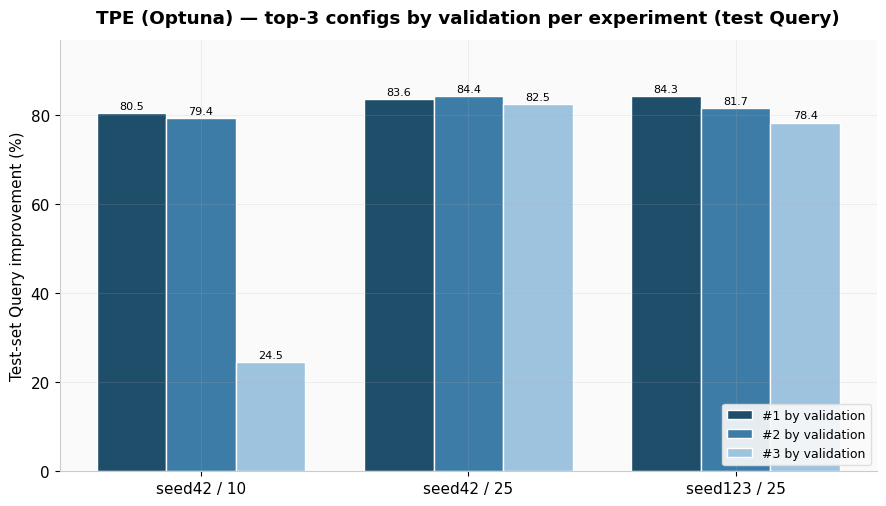

In [14]:
# D-plot — TPE summary plot across experiments (reads CSV; test set, both objectives)
algo_summary_plot('hp', 'TPE (Optuna)', PALETTE['tpe'])

In [15]:
# E01 — Install SMAC (via OptunaHub)
import subprocess, sys
print("Installing SMAC + OptunaHub...")
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'optunahub', 'smac', 'cmaes'], check=False)
import os
os.system('apt-get install -y -q swig > /dev/null 2>&1')   # swig may be needed by SMAC
print("OK — checking import...")
import optunahub
smac_mod = optunahub.load_module("samplers/smac_sampler")
SMACSampler = smac_mod.SMACSampler
print("\u2713 SMACSampler ready")

Installing SMAC + OptunaHub...
OK — checking import...
✓ SMACSampler ready


In [16]:
# E02 — run_experiment_smac: same core as TPE, but with SMACSampler (RF surrogate)
# Optimizer minimizes the VALIDATION objective; metrics -> CSV, curves -> .npz.
def run_experiment_smac(seed, n_trials, tag, objective='total'):
    csv_path    = os.path.join(DRIVE_PATH, f'smac_{objective}_{tag}.csv')
    curves_path = os.path.join(CURVES_DIR, f'smac_{objective}_{tag}_curves.npz')

    if os.path.exists(csv_path):
        existing = pd.read_csv(csv_path)
        if len(existing) >= n_trials:
            best = existing.loc[existing['obj_val'].idxmin()]
            print(f"[SMAC {objective}/{tag}] Already complete ({len(existing)} trials) — loading")
            print(f"  Best: test Query={best.query_impr_test:.1f}% Total={best.total_impr_test:.1f}% | Trial#{int(best.trial)}")
            return existing

    results = []
    curves  = {}
    def objective_fn(trial):
        config = {
            'embed_dim': trial.suggest_categorical('embed_dim', [16, 32, 64]),
            'hid1_size': trial.suggest_categorical('hid1_size', [32, 64, 128]),
            'hid2_size': trial.suggest_categorical('hid2_size', [32, 64, 128]),
            'pred_hid':  trial.suggest_categorical('pred_hid', [32, 64, 128, 256]),
            'lr':        trial.suggest_float('lr', 1e-4, 1e-2, log=True),
            'epochs':    trial.suggest_categorical('epochs', [100, 150, 200]),
        }
        t0 = time.time()
        res = run_avgdl_full(config, objective=objective, verbose=False)
        elapsed = (time.time() - t0) / 60
        if res is None:
            score = 99999.0
            print(f"  Trial {trial.number+1} | OOM | {elapsed:.1f}m")
            row = {**config, 'obj_val': score, 'trial': trial.number+1, 'time_min': round(elapsed,2)}
        else:
            val_impr = res['query_impr_val'] if objective=='query' else res['total_impr_val']
            score = -val_impr
            curves[f'trial_{trial.number+1}'] = res['curve']
            print(f"  Trial {trial.number+1:2d} | emb={config['embed_dim']:3d} "
                  f"h1={config['hid1_size']:3d} h2={config['hid2_size']:3d} ph={config['pred_hid']:3d} | "
                  f"val={val_impr:.1f}% | test(Q)={res['query_impr_test']:.1f}% "
                  f"test(T)={res['total_impr_test']:.1f}% | {elapsed:.1f}m")
            row = {**config, 'obj_val': round(score,3), 'trial': trial.number+1,
                   'time_min': round(elapsed,2),
                   'query_time': round(res['query_time'],2), 'total_time': round(res['total_time'],2),
                   'query_impr_val':  round(res['query_impr_val'],2),
                   'query_impr_test': round(res['query_impr_test'],2),
                   'query_impr_full': round(res['query_impr_full'],2),
                   'total_impr_val':  round(res['total_impr_val'],2),
                   'total_impr_test': round(res['total_impr_test'],2),
                   'total_impr_full': round(res['total_impr_full'],2)}
        results.append(row)
        pd.DataFrame(results).to_csv(csv_path, index=False)
        np.savez(curves_path, **curves)
        return score

    # SMACSampler needs the search space up front
    search_space = {
        'embed_dim': optuna.distributions.CategoricalDistribution([16, 32, 64]),
        'hid1_size': optuna.distributions.CategoricalDistribution([32, 64, 128]),
        'hid2_size': optuna.distributions.CategoricalDistribution([32, 64, 128]),
        'pred_hid':  optuna.distributions.CategoricalDistribution([32, 64, 128, 256]),
        'lr':        optuna.distributions.FloatDistribution(1e-4, 1e-2, log=True),
        'epochs':    optuna.distributions.CategoricalDistribution([100, 150, 200]),
    }
    sampler = SMACSampler(search_space, n_trials=n_trials, seed=seed)
    print(f"EXPERIMENT (SMAC): objective={objective}, seed={seed}, {n_trials} trials (tag={tag})\n")
    study = optuna.create_study(direction='minimize', sampler=sampler)
    study.optimize(objective_fn, n_trials=n_trials)

    df = pd.DataFrame(results)
    df.sort_values('obj_val').to_csv(os.path.join(DRIVE_PATH, f'smac_{objective}_{tag}_final.csv'), index=False)
    best = df.loc[df['obj_val'].idxmin()]
    print(f"\n{'='*60}")
    print(f"[SMAC {objective}/{tag}] BEST (by validation): "
          f"emb={int(best.embed_dim)} h1={int(best.hid1_size)} "
          f"h2={int(best.hid2_size)} ph={int(best.pred_hid)} | "
          f"test Query={best.query_impr_test:.1f}% Total={best.total_impr_test:.1f}% | Trial#{int(best.trial)}")
    return df

print("OK: run_experiment_smac defined (validation-driven, dual-objective, saves curves)")

OK: run_experiment_smac defined (validation-driven, dual-objective, saves curves)


In [ ]:
# E1 (total) — SMAC: 10 trials, seed=42
smac_10_total = run_experiment_smac(seed=42, n_trials=10, tag='seed42_10', objective='total')

[INFO][abstract_initial_design.py:143] Using 2 initial design configurations and 0 additional configurations.
EXPERIMENT (SMAC): objective=total, seed=42, 10 trials (tag=seed42_10)

[INFO][abstract_intensifier.py:313] Using only one seed for deterministic scenario.
  Trial  1 | emb= 64 h1=128 h2= 64 ph=256 | val=22.0% | test(Q)=80.1% test(T)=74.6% | 7.9m
[INFO][abstract_intensifier.py:523] Added config e95c12 as new incumbent because there are no incumbents yet.
  Trial  2 | emb= 16 h1= 32 h2=128 ph= 64 | val=-5.0% | test(Q)=35.3% test(T)=27.9% | 11.0m
  Trial  3 | emb= 64 h1=128 h2= 32 ph=256 | val=31.2% | test(Q)=68.5% test(T)=63.1% | 7.9m
[INFO][abstract_intensifier.py:630] Added config c47930 and rejected config e95c12 as incumbent because it is not better than the incumbents on 1 instances: 
  Trial  4 | emb= 16 h1=128 h2= 64 ph=256 | val=24.4% | test(Q)=77.1% test(T)=71.6% | 7.8m
  Trial  5 | emb= 64 h1= 32 h2= 32 ph=256 | val=16.8% | test(Q)=60.4% test(T)=54.3% | 8.7m
  Trial  6

In [ ]:
# E2 (total) — SMAC: 25 trials, seed=42
smac_25a_total = run_experiment_smac(seed=42, n_trials=25, tag='seed42_25', objective='total')

[INFO][abstract_initial_design.py:143] Using 6 initial design configurations and 0 additional configurations.
EXPERIMENT (SMAC): objective=total, seed=42, 25 trials (tag=seed42_25)

[INFO][abstract_intensifier.py:313] Using only one seed for deterministic scenario.
  Trial  1 | emb= 64 h1=128 h2= 64 ph=256 | val=21.7% | test(Q)=80.1% test(T)=74.4% | 8.3m
[INFO][abstract_intensifier.py:523] Added config e95c12 as new incumbent because there are no incumbents yet.
  Trial  2 | emb= 16 h1= 32 h2=128 ph= 64 | val=-5.0% | test(Q)=35.3% test(T)=28.0% | 11.0m
  Trial  3 | emb= 32 h1= 64 h2= 32 ph= 32 | val=28.9% | test(Q)=82.3% test(T)=77.3% | 7.3m
[INFO][abstract_intensifier.py:630] Added config e8bfab and rejected config e95c12 as incumbent because it is not better than the incumbents on 1 instances: 
  Trial  4 | emb= 64 h1= 32 h2= 64 ph=128 | val=25.0% | test(Q)=83.0% test(T)=75.8% | 10.4m
  Trial  5 | emb= 32 h1= 64 h2= 64 ph=256 | val=0.8% | test(Q)=73.5% test(T)=67.1% | 9.2m
  Trial  6

In [ ]:
# E3 (total) — SMAC: 25 trials, seed=123
smac_25b_total = run_experiment_smac(seed=123, n_trials=25, tag='seed123_25', objective='total')

[INFO][abstract_initial_design.py:91] Reducing the number of initial configurations from 60 to 6 (max_ratio == 0.25).
[INFO][abstract_initial_design.py:143] Using 6 initial design configurations and 0 additional configurations.
EXPERIMENT (SMAC): objective=total, seed=123, 25 trials (tag=seed123_25)

[INFO][abstract_intensifier.py:313] Using only one seed for deterministic scenario.
  Trial  1 | emb= 64 h1= 32 h2=128 ph= 64 | val=-4.7% | test(Q)=63.1% test(T)=56.7% | 9.0m
[INFO][abstract_intensifier.py:523] Added config dfda30 as new incumbent because there are no incumbents yet.
  Trial  2 | emb= 32 h1=128 h2= 32 ph=128 | val=17.7% | test(Q)=65.1% test(T)=59.9% | 7.5m
[INFO][abstract_intensifier.py:630] Added config 946a51 and rejected config dfda30 as incumbent because it is not better than the incumbents on 1 instances: 
  Trial  3 | emb= 16 h1= 32 h2= 64 ph=256 | val=-4.4% | test(Q)=56.4% test(T)=49.3% | 10.2m
  Trial  4 | emb= 32 h1= 64 h2= 32 ph= 32 | val=13.7% | test(Q)=80.2% te

In [ ]:
# E4 (query) — SMAC: 10 trials, seed=42
smac_10_query = run_experiment_smac(seed=42, n_trials=10, tag='seed42_10', objective='query')

[INFO][abstract_initial_design.py:143] Using 2 initial design configurations and 0 additional configurations.
EXPERIMENT (SMAC): objective=query, seed=42, 10 trials (tag=seed42_10)

[INFO][abstract_intensifier.py:313] Using only one seed for deterministic scenario.
  Trial  1 | emb= 64 h1=128 h2= 64 ph=256 | val=28.6% | test(Q)=80.1% test(T)=74.7% | 7.8m
[INFO][abstract_intensifier.py:523] Added config e95c12 as new incumbent because there are no incumbents yet.
  Trial  2 | emb= 16 h1= 32 h2=128 ph= 64 | val=4.5% | test(Q)=35.3% test(T)=28.1% | 10.8m
  Trial  3 | emb= 64 h1=128 h2= 32 ph=256 | val=10.9% | test(Q)=70.4% test(T)=65.1% | 7.6m
  Trial  4 | emb= 64 h1=128 h2= 32 ph=256 | val=33.2% | test(Q)=81.4% test(T)=74.8% | 9.3m
[INFO][abstract_intensifier.py:630] Added config 83a654 and rejected config e95c12 as incumbent because it is not better than the incumbents on 1 instances: 
  Trial  5 | emb= 64 h1=128 h2= 32 ph=256 | val=31.2% | test(Q)=78.7% test(T)=72.2% | 9.3m
  Trial  6 

In [ ]:
# E5 (query) — SMAC: 25 trials, seed=42
smac_25a_query = run_experiment_smac(seed=42, n_trials=25, tag='seed42_25', objective='query')

[INFO][abstract_initial_design.py:143] Using 6 initial design configurations and 0 additional configurations.
EXPERIMENT (SMAC): objective=query, seed=42, 25 trials (tag=seed42_25)

[INFO][abstract_intensifier.py:313] Using only one seed for deterministic scenario.
  Trial  1 | emb= 64 h1=128 h2= 64 ph=256 | val=28.6% | test(Q)=80.1% test(T)=74.8% | 7.8m
[INFO][abstract_intensifier.py:523] Added config e95c12 as new incumbent because there are no incumbents yet.
  Trial  2 | emb= 16 h1= 32 h2=128 ph= 64 | val=4.5% | test(Q)=35.3% test(T)=28.1% | 10.7m
  Trial  3 | emb= 32 h1= 64 h2= 32 ph= 32 | val=35.0% | test(Q)=82.3% test(T)=77.4% | 7.2m
[INFO][abstract_intensifier.py:630] Added config e8bfab and rejected config e95c12 as incumbent because it is not better than the incumbents on 1 instances: 
  Trial  4 | emb= 64 h1= 32 h2= 64 ph=128 | val=33.8% | test(Q)=83.0% test(T)=76.0% | 10.2m
  Trial  5 | emb= 32 h1= 64 h2= 64 ph=256 | val=8.5% | test(Q)=73.5% test(T)=67.4% | 8.8m
  Trial  6 

In [ ]:
# E6 (query) — SMAC: 25 trials, seed=123
smac_25b_query = run_experiment_smac(seed=123, n_trials=25, tag='seed123_25', objective='query')

[INFO][abstract_initial_design.py:91] Reducing the number of initial configurations from 60 to 6 (max_ratio == 0.25).
[INFO][abstract_initial_design.py:143] Using 6 initial design configurations and 0 additional configurations.
EXPERIMENT (SMAC): objective=query, seed=123, 25 trials (tag=seed123_25)

[INFO][abstract_intensifier.py:313] Using only one seed for deterministic scenario.
  Trial  1 | emb= 64 h1= 32 h2=128 ph= 64 | val=2.8% | test(Q)=63.1% test(T)=56.7% | 9.1m
[INFO][abstract_intensifier.py:523] Added config dfda30 as new incumbent because there are no incumbents yet.
  Trial  2 | emb= 32 h1=128 h2= 32 ph=128 | val=24.0% | test(Q)=65.1% test(T)=59.9% | 7.5m
[INFO][abstract_intensifier.py:630] Added config 946a51 and rejected config dfda30 as incumbent because it is not better than the incumbents on 1 instances: 
  Trial  3 | emb= 16 h1= 32 h2= 64 ph=256 | val=4.2% | test(Q)=56.4% test(T)=49.3% | 10.2m
  Trial  4 | emb= 32 h1= 64 h2= 32 ph= 32 | val=21.0% | test(Q)=80.2% test

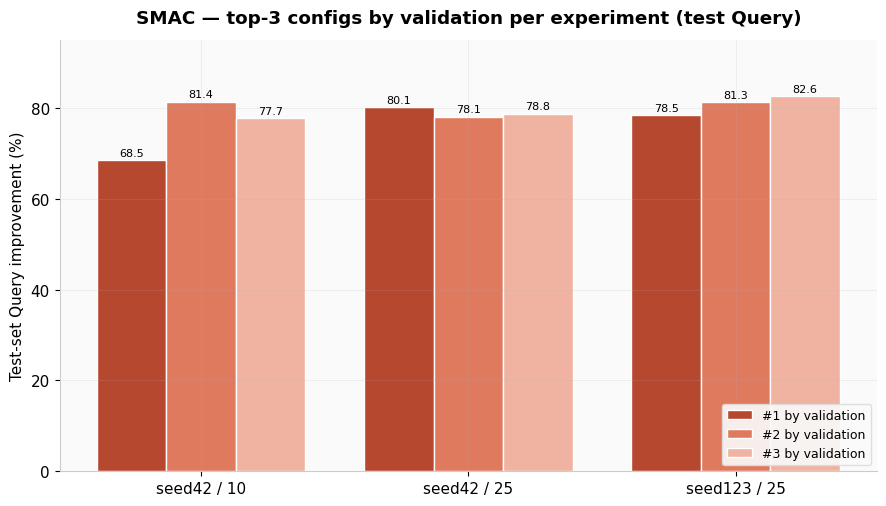

In [17]:
# E-plot — SMAC summary across experiments (reads CSV; test set, both objectives)
algo_summary_plot('smac', 'SMAC', PALETTE['smac'])

In [18]:
# F0 — run_experiment_random: same core as TPE, but with RandomSampler (blind baseline)
# Optimizer minimizes the VALIDATION objective; metrics -> CSV, curves -> .npz.
def run_experiment_random(seed, n_trials, tag, objective='total'):
    csv_path    = os.path.join(DRIVE_PATH, f'random_{objective}_{tag}.csv')
    curves_path = os.path.join(CURVES_DIR, f'random_{objective}_{tag}_curves.npz')

    if os.path.exists(csv_path):
        existing = pd.read_csv(csv_path)
        if len(existing) >= n_trials:
            best = existing.loc[existing['obj_val'].idxmin()]
            print(f"[RANDOM {objective}/{tag}] Already complete ({len(existing)} trials) — loading")
            print(f"  Best: test Query={best.query_impr_test:.1f}% Total={best.total_impr_test:.1f}% | Trial#{int(best.trial)}")
            return existing

    results = []
    curves  = {}
    def objective_fn(trial):
        config = {
            'embed_dim': trial.suggest_categorical('embed_dim', [16, 32, 64]),
            'hid1_size': trial.suggest_categorical('hid1_size', [32, 64, 128]),
            'hid2_size': trial.suggest_categorical('hid2_size', [32, 64, 128]),
            'pred_hid':  trial.suggest_categorical('pred_hid', [32, 64, 128, 256]),
            'lr':        trial.suggest_float('lr', 1e-4, 1e-2, log=True),
            'epochs':    trial.suggest_categorical('epochs', [100, 150, 200]),
        }
        t0 = time.time()
        res = run_avgdl_full(config, objective=objective, verbose=False)
        elapsed = (time.time() - t0) / 60
        if res is None:
            score = 99999.0
            print(f"  Trial {trial.number+1} | OOM | {elapsed:.1f}m")
            row = {**config, 'obj_val': score, 'trial': trial.number+1, 'time_min': round(elapsed,2)}
        else:
            val_impr = res['query_impr_val'] if objective=='query' else res['total_impr_val']
            score = -val_impr
            curves[f'trial_{trial.number+1}'] = res['curve']
            print(f"  Trial {trial.number+1:2d} | emb={config['embed_dim']:3d} "
                  f"h1={config['hid1_size']:3d} h2={config['hid2_size']:3d} ph={config['pred_hid']:3d} | "
                  f"val={val_impr:.1f}% | test(Q)={res['query_impr_test']:.1f}% "
                  f"test(T)={res['total_impr_test']:.1f}% | {elapsed:.1f}m")
            row = {**config, 'obj_val': round(score,3), 'trial': trial.number+1,
                   'time_min': round(elapsed,2),
                   'query_time': round(res['query_time'],2), 'total_time': round(res['total_time'],2),
                   'query_impr_val':  round(res['query_impr_val'],2),
                   'query_impr_test': round(res['query_impr_test'],2),
                   'query_impr_full': round(res['query_impr_full'],2),
                   'total_impr_val':  round(res['total_impr_val'],2),
                   'total_impr_test': round(res['total_impr_test'],2),
                   'total_impr_full': round(res['total_impr_full'],2)}
        results.append(row)
        pd.DataFrame(results).to_csv(csv_path, index=False)
        np.savez(curves_path, **curves)
        return score

    print(f"EXPERIMENT (Random): objective={objective}, seed={seed}, {n_trials} trials (tag={tag})\n")
    study = optuna.create_study(direction='minimize',
                                sampler=optuna.samplers.RandomSampler(seed=seed))
    study.optimize(objective_fn, n_trials=n_trials)

    df = pd.DataFrame(results)
    df.sort_values('obj_val').to_csv(os.path.join(DRIVE_PATH, f'random_{objective}_{tag}_final.csv'), index=False)
    best = df.loc[df['obj_val'].idxmin()]
    print(f"\n{'='*60}")
    print(f"[RANDOM {objective}/{tag}] BEST (by validation): "
          f"emb={int(best.embed_dim)} h1={int(best.hid1_size)} "
          f"h2={int(best.hid2_size)} ph={int(best.pred_hid)} | "
          f"test Query={best.query_impr_test:.1f}% Total={best.total_impr_test:.1f}% | Trial#{int(best.trial)}")
    return df

print("OK: run_experiment_random defined (validation-driven, dual-objective, saves curves)")

OK: run_experiment_random defined (validation-driven, dual-objective, saves curves)


In [ ]:
# F1 (total) — Random: 10 trials, seed=42
random_10_total = run_experiment_random(seed=42, n_trials=10, tag='seed42_10', objective='total')

EXPERIMENT (Random): objective=total, seed=42, 10 trials (tag=seed42_10)

  Trial  1 | emb= 32 h1= 32 h2= 64 ph=128 | val=-9.6% | test(Q)=79.2% test(T)=72.1% | 10.5m
  Trial  2 | emb= 16 h1= 32 h2=128 ph=128 | val=6.3% | test(Q)=76.2% test(T)=68.6% | 11.0m
  Trial  3 | emb= 16 h1= 64 h2= 64 ph= 32 | val=5.8% | test(Q)=62.1% test(T)=54.7% | 10.8m
  Trial  4 | emb= 32 h1= 64 h2=128 ph=128 | val=22.1% | test(Q)=80.5% test(T)=72.8% | 11.1m
  Trial  5 | emb= 32 h1=128 h2=128 ph=256 | val=10.4% | test(Q)=66.9% test(T)=61.5% | 7.9m
  Trial  6 | emb= 32 h1= 32 h2= 64 ph= 32 | val=18.0% | test(Q)=79.4% test(T)=72.0% | 10.9m
  Trial  7 | emb= 64 h1=128 h2=128 ph= 64 | val=-26.6% | test(Q)=78.4% test(T)=70.3% | 11.6m
  Trial  8 | emb= 64 h1= 32 h2=128 ph= 64 | val=17.4% | test(Q)=24.5% test(T)=18.3% | 9.1m
  Trial  9 | emb= 32 h1= 32 h2= 32 ph= 64 | val=11.0% | test(Q)=85.5% test(T)=80.4% | 7.5m
  Trial 10 | emb= 32 h1= 64 h2= 32 ph=256 | val=-5.0% | test(Q)=74.0% test(T)=66.5% | 10.8m

[RANDOM t

In [ ]:
# F2 (total) — Random: 25 trials, seed=42
random_25a_total = run_experiment_random(seed=42, n_trials=25, tag='seed42_25', objective='total')

EXPERIMENT (Random): objective=total, seed=42, 25 trials (tag=seed42_25)

  Trial  1 | emb= 32 h1= 32 h2= 64 ph=128 | val=-9.5% | test(Q)=79.2% test(T)=72.1% | 10.5m
  Trial  2 | emb= 16 h1= 32 h2=128 ph=128 | val=6.3% | test(Q)=76.2% test(T)=68.5% | 11.0m
  Trial  3 | emb= 16 h1= 64 h2= 64 ph= 32 | val=5.8% | test(Q)=62.1% test(T)=54.7% | 10.8m
  Trial  4 | emb= 32 h1= 64 h2=128 ph=128 | val=22.0% | test(Q)=80.5% test(T)=72.8% | 11.1m
  Trial  5 | emb= 32 h1=128 h2=128 ph=256 | val=10.4% | test(Q)=66.9% test(T)=61.4% | 7.9m
  Trial  6 | emb= 32 h1= 32 h2= 64 ph= 32 | val=18.0% | test(Q)=79.4% test(T)=71.9% | 10.9m
  Trial  7 | emb= 64 h1=128 h2=128 ph= 64 | val=-26.7% | test(Q)=78.4% test(T)=70.2% | 11.6m
  Trial  8 | emb= 64 h1= 32 h2=128 ph= 64 | val=17.4% | test(Q)=24.5% test(T)=18.2% | 9.1m
  Trial  9 | emb= 32 h1= 32 h2= 32 ph= 64 | val=11.0% | test(Q)=85.5% test(T)=80.4% | 7.5m
  Trial 10 | emb= 32 h1= 64 h2= 32 ph=256 | val=-5.1% | test(Q)=74.0% test(T)=66.2% | 11.0m
  Trial 11

In [ ]:
# F3 (total) — Random: 25 trials, seed=123
random_25b_total = run_experiment_random(seed=123, n_trials=25, tag='seed123_25', objective='total')

EXPERIMENT (Random): objective=total, seed=123, 25 trials (tag=seed123_25)

  Trial  1 | emb= 16 h1= 64 h2= 32 ph=128 | val=0.9% | test(Q)=19.3% test(T)=13.1% | 9.0m
  Trial  2 | emb= 64 h1= 64 h2= 64 ph=256 | val=16.9% | test(Q)=76.2% test(T)=68.9% | 10.6m
  Trial  3 | emb= 64 h1= 64 h2= 32 ph= 64 | val=-18.5% | test(Q)=76.2% test(T)=70.0% | 9.1m
  Trial  4 | emb= 16 h1=128 h2= 64 ph=256 | val=-6.5% | test(Q)=60.4% test(T)=53.6% | 9.7m
  Trial  5 | emb= 32 h1= 32 h2= 64 ph=128 | val=-13.4% | test(Q)=84.6% test(T)=77.3% | 10.4m
  Trial  6 | emb= 16 h1=128 h2= 32 ph= 64 | val=19.8% | test(Q)=35.2% test(T)=27.7% | 11.0m
  Trial  7 | emb= 64 h1= 64 h2= 32 ph=128 | val=29.4% | test(Q)=82.3% test(T)=77.3% | 7.3m
  Trial  8 | emb= 16 h1=128 h2= 32 ph= 32 | val=-5.7% | test(Q)=77.1% test(T)=70.7% | 9.2m
  Trial  9 | emb= 64 h1= 32 h2= 32 ph= 32 | val=33.8% | test(Q)=81.7% test(T)=75.8% | 8.6m
  Trial 10 | emb= 32 h1= 64 h2=128 ph=256 | val=21.4% | test(Q)=76.5% test(T)=71.4% | 7.4m
  Trial 11

In [ ]:
# F4 (query) — Random: 10 trials, seed=42
random_10_query = run_experiment_random(seed=42, n_trials=10, tag='seed42_10', objective='query')

EXPERIMENT (Random): objective=query, seed=42, 10 trials (tag=seed42_10)

  Trial  1 | emb= 32 h1= 32 h2= 64 ph=128 | val=-0.6% | test(Q)=79.2% test(T)=71.9% | 10.7m
  Trial  2 | emb= 16 h1= 32 h2=128 ph=128 | val=15.6% | test(Q)=76.2% test(T)=68.8% | 10.8m
  Trial  3 | emb= 16 h1= 64 h2= 64 ph= 32 | val=15.0% | test(Q)=62.1% test(T)=55.0% | 10.4m
  Trial  4 | emb= 32 h1= 64 h2=128 ph=128 | val=31.5% | test(Q)=80.5% test(T)=73.1% | 10.7m
  Trial  5 | emb= 32 h1=128 h2=128 ph=256 | val=17.0% | test(Q)=66.9% test(T)=61.5% | 7.7m
  Trial  6 | emb= 32 h1= 32 h2= 64 ph= 32 | val=27.3% | test(Q)=79.4% test(T)=71.7% | 11.2m
  Trial  7 | emb= 64 h1=128 h2=128 ph= 64 | val=-16.8% | test(Q)=78.4% test(T)=69.9% | 12.1m
  Trial  8 | emb= 64 h1= 32 h2=128 ph= 64 | val=25.1% | test(Q)=24.5% test(T)=18.0% | 9.5m
  Trial  9 | emb= 32 h1= 32 h2= 32 ph= 64 | val=17.3% | test(Q)=85.5% test(T)=80.2% | 7.8m
  Trial 10 | emb= 32 h1= 64 h2= 32 ph=256 | val=4.1% | test(Q)=74.0% test(T)=66.1% | 11.3m

[RANDOM 

In [ ]:
# F5 (query) — Random: 25 trials, seed=42
random_25a_query = run_experiment_random(seed=42, n_trials=25, tag='seed42_25', objective='query')

EXPERIMENT (Random): objective=query, seed=42, 25 trials (tag=seed42_25)

  Trial  1 | emb= 32 h1= 32 h2= 64 ph=128 | val=-0.6% | test(Q)=79.2% test(T)=71.8% | 10.9m
  Trial  2 | emb= 16 h1= 32 h2=128 ph=128 | val=15.6% | test(Q)=76.2% test(T)=68.4% | 11.3m
  Trial  3 | emb= 16 h1= 64 h2= 64 ph= 32 | val=15.0% | test(Q)=62.1% test(T)=54.6% | 11.0m
  Trial  4 | emb= 32 h1= 64 h2=128 ph=128 | val=31.5% | test(Q)=80.5% test(T)=72.3% | 11.5m
  Trial  5 | emb= 32 h1=128 h2=128 ph=256 | val=17.0% | test(Q)=66.9% test(T)=61.0% | 8.6m
  Trial  6 | emb= 32 h1= 32 h2= 64 ph= 32 | val=27.3% | test(Q)=79.4% test(T)=71.4% | 11.8m
  Trial  7 | emb= 64 h1=128 h2=128 ph= 64 | val=-16.8% | test(Q)=78.4% test(T)=70.0% | 12.1m
  Trial  8 | emb= 64 h1= 32 h2=128 ph= 64 | val=25.1% | test(Q)=24.5% test(T)=18.0% | 9.4m
  Trial  9 | emb= 32 h1= 32 h2= 32 ph= 64 | val=17.3% | test(Q)=85.5% test(T)=80.2% | 7.8m
  Trial 10 | emb= 32 h1= 64 h2= 32 ph=256 | val=4.1% | test(Q)=74.0% test(T)=65.9% | 11.5m
  Trial 1

In [ ]:
# F6 (query) — Random: 25 trials, seed=123
random_25b_query = run_experiment_random(seed=123, n_trials=25, tag='seed123_25', objective='query')

EXPERIMENT (Random): objective=query, seed=123, 25 trials (tag=seed123_25)

  Trial  1 | emb= 16 h1= 64 h2= 32 ph=128 | val=8.5% | test(Q)=19.3% test(T)=12.9% | 9.2m
  Trial  2 | emb= 64 h1= 64 h2= 64 ph=256 | val=25.9% | test(Q)=76.2% test(T)=68.0% | 11.8m
  Trial  3 | emb= 64 h1= 64 h2= 32 ph= 64 | val=-10.9% | test(Q)=76.2% test(T)=69.4% | 10.0m
  Trial  4 | emb= 16 h1=128 h2= 64 ph=256 | val=1.7% | test(Q)=60.4% test(T)=53.5% | 10.1m
  Trial  5 | emb= 32 h1= 32 h2= 64 ph=128 | val=-4.6% | test(Q)=84.6% test(T)=77.2% | 10.5m
  Trial  6 | emb= 16 h1=128 h2= 32 ph= 64 | val=29.1% | test(Q)=35.2% test(T)=27.7% | 11.0m
  Trial  7 | emb= 64 h1= 64 h2= 32 ph=128 | val=35.5% | test(Q)=82.3% test(T)=77.3% | 7.4m
  Trial  8 | emb= 16 h1=128 h2= 32 ph= 32 | val=2.1% | test(Q)=77.1% test(T)=70.5% | 9.5m
  Trial  9 | emb= 64 h1= 32 h2= 32 ph= 32 | val=41.0% | test(Q)=81.7% test(T)=75.7% | 8.9m
  Trial 10 | emb= 32 h1= 64 h2=128 ph=256 | val=27.6% | test(Q)=76.5% test(T)=71.5% | 7.4m
  Trial 11 

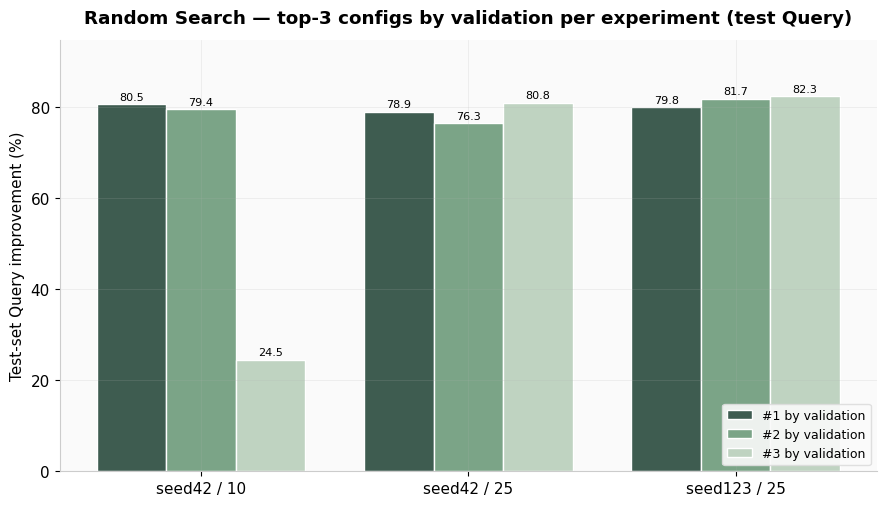

In [19]:
# F-plot — Random Search summary across experiments (reads CSV; test set, both objectives)
algo_summary_plot('random', 'Random Search', PALETTE['random'])

In [20]:
# G1 (corrected) — TOP-3 distinct configs per algorithm, selected by VALIDATION-Query,
# pooled across all 6 search files.
CONFIG_COLS = ['embed_dim','hid1_size','hid2_size','pred_hid','lr','epochs']
SEL_VAL = 'query_impr_val'          # selection criterion: validation-Query (primary metric)

def gather_algo_configs(prefix):
    frames = []
    for objective in ['total','query']:
        for tag in ['seed42_10','seed42_25','seed123_25']:
            fn = os.path.join(DRIVE_PATH, f'{prefix}_{objective}_{tag}.csv')
            if os.path.exists(fn):
                d = pd.read_csv(fn); d['src'] = f'{objective}/{tag}'
                frames.append(d)
    if not frames:
        return None
    alld = pd.concat(frames, ignore_index=True)
    alld = alld[alld['obj_val'] < 9999].copy()
    alld = alld.sort_values(SEL_VAL, ascending=False)               # rank by VALIDATION-Query, not test
    alld = alld.drop_duplicates(subset=CONFIG_COLS, keep='first')   # distinct configs
    return alld

def top3_for_reruns(prefix, algo_name):
    alld = gather_algo_configs(prefix)
    if alld is None or len(alld) == 0:
        print(f"[{algo_name}] no data")
        return []
    top = alld.head(3)
    print(f"\n=== {algo_name}: TOP-3 distinct configs (selected by validation-Query) ===")
    out = []
    for rank, (_, r) in enumerate(top.iterrows(), 1):
        cfg = {c: (float(r[c]) if c == 'lr' else int(r[c])) for c in CONFIG_COLS}
        print(f"  #{rank}: emb={cfg['embed_dim']} h1={cfg['hid1_size']} h2={cfg['hid2_size']} ph={cfg['pred_hid']} lr={cfg['lr']:.6f} ep={cfg['epochs']} | val(Q)={r.query_impr_val:.1f}%  (test(Q)={r.query_impr_test:.1f}% ref) [{r.src}]")
        out.append({'algo': algo_name, 'rank': rank, **cfg})
    if len(top) < 3:
        print(f"  WARNING: only {len(top)} distinct configs for {algo_name}")
    return out

RERUN_CONFIGS = []
for prefix, name in [('hp', 'TPE'), ('smac', 'SMAC'), ('random', 'Random')]:
    RERUN_CONFIGS += top3_for_reruns(prefix, name)

# authors' manual baseline (unchanged)
RERUN_CONFIGS.append({'algo': 'Baseline', 'rank': 0, 'embed_dim': 32, 'hid1_size': 64,
                      'hid2_size': 64, 'pred_hid': 64, 'lr': 0.001, 'epochs': 100})

print("\n" + "=" * 60)
print(f"TOTAL configs for reruns: {len(RERUN_CONFIGS)}  ->  {len(RERUN_CONFIGS) * 5} reruns (5 training seeds each)")

# cross-algorithm duplicate check (informational)
seen = {}
for c in RERUN_CONFIGS:
    key = tuple(c[k] for k in CONFIG_COLS)
    seen.setdefault(key, []).append(c['algo'])
dups = {k: v for k, v in seen.items() if len(v) > 1}
if dups:
    print(f"Shared across algorithms: {list(dups.values())}")
else:
    print("No cross-algorithm duplicates.")


=== TPE: TOP-3 distinct configs (selected by validation-Query) ===
  #1: emb=64 h1=32 h2=64 ph=32 lr=0.000451 ep=150 | val(Q)=51.8%  (test(Q)=83.6% ref) [total/seed42_25]
  #2: emb=64 h1=32 h2=64 ph=32 lr=0.000435 ep=150 | val(Q)=50.1%  (test(Q)=84.4% ref) [query/seed42_25]
  #3: emb=64 h1=32 h2=64 ph=32 lr=0.000285 ep=100 | val(Q)=47.1%  (test(Q)=82.5% ref) [total/seed42_25]

=== SMAC: TOP-3 distinct configs (selected by validation-Query) ===
  #1: emb=32 h1=64 h2=32 ph=32 lr=0.000492 ep=150 | val(Q)=47.9%  (test(Q)=80.1% ref) [query/seed42_25]
  #2: emb=32 h1=64 h2=32 ph=32 lr=0.000492 ep=150 | val(Q)=45.4%  (test(Q)=78.1% ref) [query/seed42_25]
  #3: emb=32 h1=64 h2=32 ph=32 lr=0.000493 ep=100 | val(Q)=44.7%  (test(Q)=78.8% ref) [query/seed42_25]

=== Random: TOP-3 distinct configs (selected by validation-Query) ===
  #1: emb=32 h1=64 h2=32 ph=64 lr=0.001217 ep=200 | val(Q)=45.5%  (test(Q)=79.8% ref) [total/seed123_25]
  #2: emb=16 h1=32 h2=64 ph=64 lr=0.003112 ep=150 | val(Q)=45.0

In [21]:
# ============================================================
# D7 — Top-3 distinct configs per algorithm, ranked by VALIDATION,
#      pooled over all 6 search files.
# Two selection variants, for comparison:
#   A) query_impr_val for every run
#   B) each run's own objective (query-run -> query_impr_val,
#      total-run -> total_impr_val)
# Test scores are shown for transparency only; they do not affect ranking.
# ============================================================
import numpy as np
CONFIG_COLS = ['embed_dim','hid1_size','hid2_size','pred_hid','lr','epochs']
ALGOS = [('hp','TPE'), ('smac','SMAC'), ('random','Random')]

def _pool(prefix):
    fr=[]
    for objv in ['total','query']:
        for tag in ['seed42_10','seed42_25','seed123_25']:
            fn=os.path.join(DRIVE_PATH, f'{prefix}_{objv}_{tag}.csv')
            if os.path.exists(fn):
                d=pd.read_csv(fn); d['objective']=objv; d['source_tag']=tag; fr.append(d)
    if not fr: return None
    d=pd.concat(fr, ignore_index=True)
    return d[d['obj_val']<9999].copy()

def _sig(r): return (int(r.embed_dim),int(r.hid1_size),int(r.hid2_size),
                     int(r.pred_hid),round(float(r.lr),8),int(r.epochs))

def _top3(d, key):
    d=d.sort_values(key, ascending=False).drop_duplicates(CONFIG_COLS, keep='first')
    return d.head(3)

def _print(top, key):
    for rank,(_,r) in enumerate(top.iterrows(),1):
        print(f"  #{rank}: ed{int(r.embed_dim)} h1{int(r.hid1_size)} h2{int(r.hid2_size)} "
              f"ph{int(r.pred_hid)} lr{r.lr:.6f} ep{int(r.epochs)} | "
              f"val(Q)={r.query_impr_val:5.1f} val(T)={r.total_impr_val:5.1f} "
              f"-> test(Q)={r.query_impr_test:5.1f} [{r.objective}/{r.source_tag}]")

cands_qval, cands_objval = {}, {}
for prefix,name in ALGOS:
    d=_pool(prefix)
    if d is None: print(f"{name}: no data"); continue
    # A) validation-Query
    A=_top3(d.copy(), 'query_impr_val'); cands_qval[name]=A
    # B) objective's own validation
    d2=d.copy(); d2['own_val']=np.where(d2['objective']=='query', d2['query_impr_val'], d2['total_impr_val'])
    B=_top3(d2, 'own_val'); cands_objval[name]=B
    same = {_sig(r) for _,r in A.iterrows()} == {_sig(r) for _,r in B.iterrows()}
    print(f"\n=== {name} ===  ίδιοι υποψήφιοι στις δύο εκδοχές: {'ΝΑΙ' if same else 'ΟΧΙ'}")
    print(" A) validation-Query:"); _print(A,'query_impr_val')
    print(" B) objective's own val:"); _print(B,'own_val')


=== TPE ===  ίδιοι υποψήφιοι στις δύο εκδοχές: ΝΑΙ
 A) validation-Query:
  #1: ed64 h132 h264 ph32 lr0.000451 ep150 | val(Q)= 51.8 val(T)= 44.4 -> test(Q)= 83.6 [total/seed42_25]
  #2: ed64 h132 h264 ph32 lr0.000435 ep150 | val(Q)= 50.1 val(T)= 42.7 -> test(Q)= 84.4 [query/seed42_25]
  #3: ed64 h132 h264 ph32 lr0.000285 ep100 | val(Q)= 47.1 val(T)= 41.0 -> test(Q)= 82.5 [total/seed42_25]
 B) objective's own val:
  #1: ed64 h132 h264 ph32 lr0.000451 ep150 | val(Q)= 51.8 val(T)= 44.3 -> test(Q)= 83.6 [query/seed42_25]
  #2: ed64 h132 h264 ph32 lr0.000435 ep150 | val(Q)= 50.1 val(T)= 42.7 -> test(Q)= 84.4 [query/seed42_25]
  #3: ed64 h132 h264 ph32 lr0.000285 ep100 | val(Q)= 47.1 val(T)= 41.0 -> test(Q)= 82.5 [query/seed42_25]

=== SMAC ===  ίδιοι υποψήφιοι στις δύο εκδοχές: ΝΑΙ
 A) validation-Query:
  #1: ed32 h164 h232 ph32 lr0.000492 ep150 | val(Q)= 47.9 val(T)= 40.7 -> test(Q)= 80.1 [query/seed42_25]
  #2: ed32 h164 h232 ph32 lr0.000492 ep150 | val(Q)= 45.4 val(T)= 38.2 -> test(Q)= 7

In [22]:
# H0 — Reruns setup
RERUN_SEEDS = [0, 1, 2, 3, 4]
RERUN_CSV   = os.path.join(DRIVE_PATH, 'Reruns.csv')
SUMMARY_CSV = os.path.join(DRIVE_PATH, 'Summary_of_Reruns.csv')

RERUN_COLS = ['algo','rank','train_seed',
              'embed_dim','hid1_size','hid2_size','pred_hid','lr','epochs',
              'query_impr_test','total_impr_test',
              'query_impr_val','total_impr_val',
              'query_impr_full','total_impr_full']

def _cfg_sig(cfg):
    return (int(cfg['embed_dim']), int(cfg['hid1_size']), int(cfg['hid2_size']),
            int(cfg['pred_hid']), round(float(cfg['lr']), 8), int(cfg['epochs']))

def _load_rerun_csv():
    if os.path.exists(RERUN_CSV):
        return pd.read_csv(RERUN_CSV)
    return pd.DataFrame(columns=RERUN_COLS)

def _done_pairs(df):
    done = set()
    for _, r in df.iterrows():
        sig = (int(r['embed_dim']), int(r['hid1_size']), int(r['hid2_size']),
               int(r['pred_hid']), round(float(r['lr']), 8), int(r['epochs']))
        done.add((sig, int(r['train_seed'])))
    return done

def run_reruns_for_algo(algo_name):
    configs = [c for c in RERUN_CONFIGS if c['algo'] == algo_name]
    if not configs:
        print(f'[{algo_name}] no configs in RERUN_CONFIGS'); return
    df   = _load_rerun_csv()
    done = _done_pairs(df)
    for cfg in configs:
        sig = _cfg_sig(cfg)
        tag = (f"{algo_name} #{cfg['rank']}  "
               f"(ed{sig[0]},h1{sig[1]},h2{sig[2]},ph{sig[3]},lr{sig[4]},ep{sig[5]})")
        for s in RERUN_SEEDS:
            if (sig, s) in done:
                print(f'  skip (done): {tag}  seed={s}'); continue
            print(f'  run: {tag}  seed={s} ...', end=' ', flush=True)
            run_cfg = dict(cfg); run_cfg['train_seed'] = s
            res = run_avgdl_full(run_cfg, objective='total', verbose=False)  # objective irrelevant: both metrics stored
            row = {'algo': algo_name, 'rank': cfg['rank'], 'train_seed': s,
                   'embed_dim': sig[0], 'hid1_size': sig[1], 'hid2_size': sig[2],
                   'pred_hid': sig[3], 'lr': cfg['lr'], 'epochs': sig[5],
                   'query_impr_test': res['query_impr_test'],
                   'total_impr_test': res['total_impr_test'],
                   'query_impr_val':  res['query_impr_val'],
                   'total_impr_val':  res['total_impr_val'],
                   'query_impr_full': res['query_impr_full'],
                   'total_impr_full': res['total_impr_full']}
            df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
            df.to_csv(RERUN_CSV, index=False)      # live save -> resumable
            done.add((sig, s))
            print(f"q_test={res['query_impr_test']:.1f}%  tot_test={res['total_impr_test']:.1f}%")
    print(f'[{algo_name}] done -> {RERUN_CSV}')

_seen, _uniq = set(), []
for c in RERUN_CONFIGS:
    sg = _cfg_sig(c)
    if sg not in _seen: _seen.add(sg); _uniq.append(c)
print('H0 ready. seeds =', RERUN_SEEDS)
print(f'RERUN_CONFIGS: {len(RERUN_CONFIGS)} entries -> {len(_uniq)} unique configs -> {len(_uniq)*len(RERUN_SEEDS)} total runs')
print('CSV     :', RERUN_CSV)
print('Summary :', SUMMARY_CSV)

H0 ready. seeds = [0, 1, 2, 3, 4]
RERUN_CONFIGS: 10 entries -> 10 unique configs -> 50 total runs
CSV     : /content/drive/MyDrive/datasets/qp_evaluation_data/Reruns.csv
Summary : /content/drive/MyDrive/datasets/qp_evaluation_data/Summary_of_Reruns.csv


In [ ]:
# H1 — TPE reruns
run_reruns_for_algo('TPE')

  run: TPE #1  (ed64,h132,h264,ph32,lr0.00045141,ep150)  seed=0 ... q_test=83.6%  tot_test=77.5%
  run: TPE #1  (ed64,h132,h264,ph32,lr0.00045141,ep150)  seed=1 ... 

/tmp/ipykernel_588/2951054562.py:54: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)


q_test=68.1%  tot_test=61.9%
  run: TPE #1  (ed64,h132,h264,ph32,lr0.00045141,ep150)  seed=2 ... q_test=87.2%  tot_test=81.1%
  run: TPE #1  (ed64,h132,h264,ph32,lr0.00045141,ep150)  seed=3 ... q_test=58.0%  tot_test=52.0%
  run: TPE #1  (ed64,h132,h264,ph32,lr0.00045141,ep150)  seed=4 ... q_test=76.8%  tot_test=70.8%
  run: TPE #2  (ed64,h132,h264,ph32,lr0.00043476,ep150)  seed=0 ... q_test=84.4%  tot_test=78.4%
  run: TPE #2  (ed64,h132,h264,ph32,lr0.00043476,ep150)  seed=1 ... q_test=60.5%  tot_test=54.3%
  run: TPE #2  (ed64,h132,h264,ph32,lr0.00043476,ep150)  seed=2 ... q_test=86.7%  tot_test=80.6%
  run: TPE #2  (ed64,h132,h264,ph32,lr0.00043476,ep150)  seed=3 ... q_test=81.4%  tot_test=75.4%
  run: TPE #2  (ed64,h132,h264,ph32,lr0.00043476,ep150)  seed=4 ... q_test=70.3%  tot_test=64.3%
  run: TPE #3  (ed64,h132,h264,ph32,lr0.00028523,ep100)  seed=0 ... q_test=82.5%  tot_test=77.4%
  run: TPE #3  (ed64,h132,h264,ph32,lr0.00028523,ep100)  seed=1 ... q_test=59.3%  tot_test=54.2%
 

In [ ]:
# H2 — SMAC reruns
run_reruns_for_algo('SMAC')

  run: SMAC #1  (ed32,h164,h232,ph32,lr0.00049216,ep150)  seed=0 ... q_test=80.1%  tot_test=74.0%
  run: SMAC #1  (ed32,h164,h232,ph32,lr0.00049216,ep150)  seed=1 ... q_test=79.7%  tot_test=73.6%
  run: SMAC #1  (ed32,h164,h232,ph32,lr0.00049216,ep150)  seed=2 ... q_test=75.9%  tot_test=69.8%
  run: SMAC #1  (ed32,h164,h232,ph32,lr0.00049216,ep150)  seed=3 ... q_test=83.4%  tot_test=77.2%
  run: SMAC #1  (ed32,h164,h232,ph32,lr0.00049216,ep150)  seed=4 ... q_test=85.6%  tot_test=79.5%
  run: SMAC #2  (ed32,h164,h232,ph32,lr0.00049185,ep150)  seed=0 ... q_test=78.1%  tot_test=72.0%
  run: SMAC #2  (ed32,h164,h232,ph32,lr0.00049185,ep150)  seed=1 ... q_test=69.9%  tot_test=63.4%
  run: SMAC #2  (ed32,h164,h232,ph32,lr0.00049185,ep150)  seed=2 ... q_test=75.9%  tot_test=69.8%
  run: SMAC #2  (ed32,h164,h232,ph32,lr0.00049185,ep150)  seed=3 ... q_test=88.2%  tot_test=81.7%
  run: SMAC #2  (ed32,h164,h232,ph32,lr0.00049185,ep150)  seed=4 ... q_test=88.2%  tot_test=82.1%
  run: SMAC #3  (ed3

In [ ]:
# H3 — Random reruns
run_reruns_for_algo('Random')

  run: Random #1  (ed32,h164,h232,ph64,lr0.00121695,ep200)  seed=0 ... q_test=79.8%  tot_test=72.7%
  run: Random #1  (ed32,h164,h232,ph64,lr0.00121695,ep200)  seed=1 ... q_test=70.3%  tot_test=63.0%
  run: Random #1  (ed32,h164,h232,ph64,lr0.00121695,ep200)  seed=2 ... q_test=84.2%  tot_test=76.9%
  run: Random #1  (ed32,h164,h232,ph64,lr0.00121695,ep200)  seed=3 ... q_test=80.5%  tot_test=73.4%
  run: Random #1  (ed32,h164,h232,ph64,lr0.00121695,ep200)  seed=4 ... q_test=84.1%  tot_test=76.9%
  run: Random #2  (ed16,h132,h264,ph64,lr0.00311159,ep150)  seed=0 ... q_test=78.9%  tot_test=72.7%
  run: Random #2  (ed16,h132,h264,ph64,lr0.00311159,ep150)  seed=1 ... q_test=61.2%  tot_test=55.2%
  run: Random #2  (ed16,h132,h264,ph64,lr0.00311159,ep150)  seed=2 ... q_test=76.8%  tot_test=70.8%
  run: Random #2  (ed16,h132,h264,ph64,lr0.00311159,ep150)  seed=3 ... q_test=77.2%  tot_test=71.1%
  run: Random #2  (ed16,h132,h264,ph64,lr0.00311159,ep150)  seed=4 ... q_test=78.0%  tot_test=71.6%


In [ ]:
# H4 — Baseline reruns
run_reruns_for_algo('Baseline')

  run: Baseline #0  (ed32,h164,h264,ph64,lr0.001,ep100)  seed=0 ... q_test=78.6%  tot_test=73.3%
  run: Baseline #0  (ed32,h164,h264,ph64,lr0.001,ep100)  seed=1 ... q_test=82.5%  tot_test=77.0%
  run: Baseline #0  (ed32,h164,h264,ph64,lr0.001,ep100)  seed=2 ... q_test=82.8%  tot_test=77.7%
  run: Baseline #0  (ed32,h164,h264,ph64,lr0.001,ep100)  seed=3 ... q_test=76.4%  tot_test=71.1%
  run: Baseline #0  (ed32,h164,h264,ph64,lr0.001,ep100)  seed=4 ... q_test=84.1%  tot_test=78.6%
[Baseline] done -> /content/drive/MyDrive/datasets/qp_evaluation_data/Reruns.csv


In [ ]:
# H5 — Reruns summary
df = _load_rerun_csv()
if df.empty:
    print('No rerun results yet - run H1-H4 first.')
else:
    df['sig'] = df.apply(lambda r: (int(r['embed_dim']),int(r['hid1_size']),int(r['hid2_size']),int(r['pred_hid']),round(float(r['lr']),8),int(r['epochs'])), axis=1)
    agg = df.groupby('sig').agg(
        n=('train_seed','nunique'),
        q_val_mean=('query_impr_val','mean'),  q_val_std=('query_impr_val','std'),
        q_test_mean=('query_impr_test','mean'),q_test_std=('query_impr_test','std'),
        t_test_mean=('total_impr_test','mean'),t_test_std=('total_impr_test','std'),
    ).reset_index()
    meta = {_cfg_sig(c): (c['algo'], c['rank']) for c in RERUN_CONFIGS}
    agg['algo'] = agg['sig'].map(lambda s: meta.get(s, ('?','?'))[0])
    agg['rank'] = agg['sig'].map(lambda s: meta.get(s, ('?','?'))[1])
    cand   = agg[agg['algo'] != 'Baseline']
    winner = cand.sort_values('q_val_mean', ascending=False).iloc[0]
    show   = agg.sort_values('q_val_mean', ascending=False)
    print('Selection = validation-Query mean over 5 seeds. Test = report only.')
    print('-' * 96)
    for _, r in show.iterrows():
        star = '  <-- WINNER' if r['sig'] == winner['sig'] else ''
        print(f"{r['algo']:9s} #{int(r['rank'])} | VAL(Q) {r['q_val_mean']:5.1f}+/-{r['q_val_std']:4.1f} | test(Q) {r['q_test_mean']:5.1f}+/-{r['q_test_std']:4.1f} | test(T) {r['t_test_mean']:5.1f}+/-{r['t_test_std']:4.1f} | seeds={int(r['n'])}{star}")
    print('-' * 96)
    print(f"WINNER: {winner['algo']} #{int(winner['rank'])} -> test(Q) {winner['q_test_mean']:.1f}+/-{winner['q_test_std']:.1f}%  test(T) {winner['t_test_mean']:.1f}+/-{winner['t_test_std']:.1f}%")
    agg.sort_values('q_val_mean', ascending=False).to_csv(SUMMARY_CSV, index=False)
    print('Saved ->', SUMMARY_CSV)

Selection = validation-Query mean over 5 seeds. Test = report only.
------------------------------------------------------------------------------------------------
SMAC      #2 | VAL(Q)  37.9+/-14.1 | test(Q)  80.0+/- 8.0 | test(T)  73.8+/- 8.0 | seeds=5  <-- WINNER
SMAC      #1 | VAL(Q)  37.0+/-15.6 | test(Q)  80.9+/- 3.7 | test(T)  74.8+/- 3.7 | seeds=5
SMAC      #3 | VAL(Q)  34.7+/-15.6 | test(Q)  76.7+/- 5.1 | test(T)  71.7+/- 5.0 | seeds=5
Random    #3 | VAL(Q)  31.2+/-18.2 | test(Q)  78.9+/- 2.1 | test(T)  73.5+/- 2.2 | seeds=5
Baseline  #0 | VAL(Q)  29.8+/- 8.8 | test(Q)  80.9+/- 3.2 | test(T)  75.5+/- 3.2 | seeds=5
Random    #1 | VAL(Q)  25.4+/-22.6 | test(Q)  79.8+/- 5.7 | test(T)  72.6+/- 5.7 | seeds=5
TPE       #1 | VAL(Q)  25.3+/-20.2 | test(Q)  74.7+/-11.9 | test(T)  68.7+/-11.8 | seeds=5
TPE       #2 | VAL(Q)  22.0+/-22.0 | test(Q)  76.6+/-11.0 | test(T)  70.6+/-11.1 | seeds=5
TPE       #3 | VAL(Q)  16.1+/-32.8 | test(Q)  69.2+/-14.3 | test(T)  64.2+/-14.2 | seeds=5
Rand

In [ ]:
# Convert rerun outputs to Excel (.xlsx) — one workbook, two sheets.
import pandas as pd, os
xlsx_path = os.path.join(DRIVE_PATH, 'Reruns.xlsx')
with pd.ExcelWriter(xlsx_path, engine='openpyxl') as xl:
    pd.read_csv(RERUN_CSV).to_excel(xl, sheet_name='Reruns', index=False)
    if os.path.exists(SUMMARY_CSV):
        pd.read_csv(SUMMARY_CSV).to_excel(xl, sheet_name='Summary', index=False)
print('Saved ->', xlsx_path)

Saved -> /content/drive/MyDrive/datasets/qp_evaluation_data/Reruns.xlsx


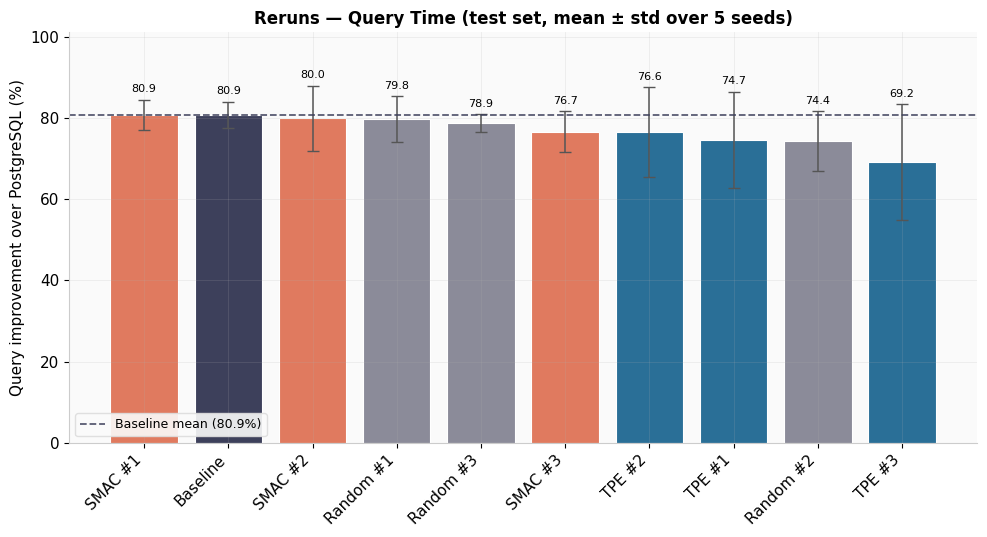

In [23]:
# H6 — Reruns (Query Time, test set): mean ± std over 5 seeds; dashed baseline reference.
df = _load_rerun_csv()
if df.empty:
    print('No rerun results yet.')
else:
    df['sig'] = df.apply(lambda r:(int(r.embed_dim),int(r.hid1_size),int(r.hid2_size),int(r.pred_hid),round(float(r.lr),8),int(r.epochs)),axis=1)
    g = df.groupby('sig').agg(q_mean=('query_impr_test','mean'), q_std=('query_impr_test','std')).to_dict('index')
    rows=[]; seen=set(); base_mean=None
    for cfg in RERUN_CONFIGS:
        sig=_cfg_sig(cfg)
        if sig not in g or sig in seen: continue
        seen.add(sig); a=g[sig]
        lab = 'Baseline' if cfg['algo']=='Baseline' else f"{cfg['algo']} #{cfg['rank']}"
        rows.append((lab, a['q_mean'], 0 if np.isnan(a['q_std']) else a['q_std'], PALETTE.get(cfg['algo'].lower(),'#888')))
        if cfg['algo']=='Baseline': base_mean=a['q_mean']
    rows.sort(key=lambda t:-t[1])
    labels=[r[0] for r in rows]; qm=[r[1] for r in rows]; qs=[r[2] for r in rows]; colors=[r[3] for r in rows]
    x=np.arange(len(labels))
    fig,ax=plt.subplots(figsize=(10,5.5))
    ax.bar(x,qm,yerr=qs,color=colors,capsize=4,edgecolor='white',linewidth=0.8,error_kw={'elinewidth':1.1,'ecolor':'#555'})
    if base_mean is not None:
        ax.axhline(base_mean, ls='--', lw=1.3, color=PALETTE['baseline'], alpha=0.85, label=f'Baseline mean ({base_mean:.1f}%)')
        ax.legend(loc='lower left', fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_ylabel('Query improvement over PostgreSQL (%)')
    top=max(v+e for v,e in zip(qm,qs)); ax.set_ylim(0, top*1.15)
    for xi,v,e in zip(x,qm,qs): ax.text(xi, v+e+top*0.015, f'{v:.1f}', ha='center', va='bottom', fontsize=8)
    ax.set_title('Reruns — Query Time (test set, mean ± std over 5 seeds)', fontsize=12, fontweight='bold')
    plt.tight_layout()
    out=os.path.join(DRIVE_PATH,'reruns_query.png'); plt.savefig(out,dpi=150,bbox_inches='tight',facecolor='white'); plt.show()

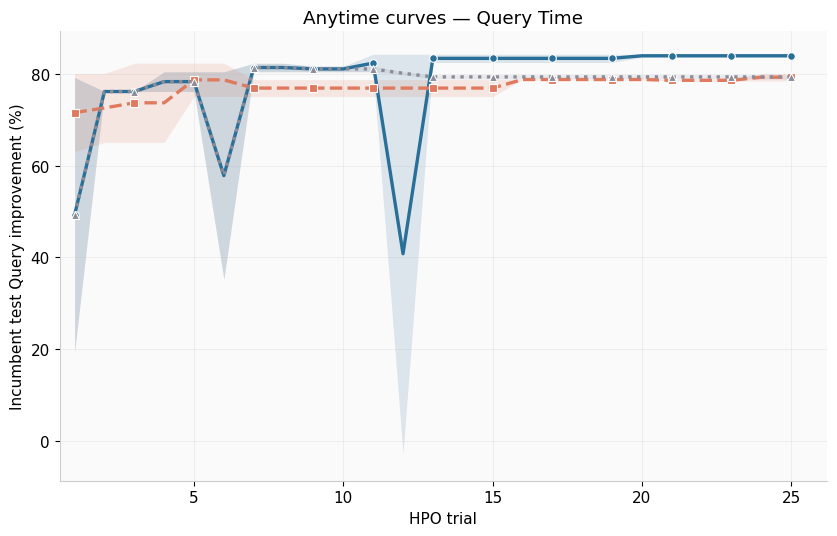

In [24]:
# I1 — Anytime curves (Query Time): incumbent chosen by VALIDATION, plotted on TEST.
# Mean over 2 search seeds, with a shaded band showing the min–max range across the two seeds.
ALGOS  = [('hp','TPE'), ('smac','SMAC'), ('random','Random')]
STYLES = {'TPE':('-','o'), 'SMAC':('--','s'), 'Random':(':','^')}

def _anytime_curve(df):
    df = df.sort_values('trial'); best_val, inc = -np.inf, np.nan; xs, ys = [], []
    for _, r in df.iterrows():
        ov = r['obj_val']
        if pd.notna(ov) and ov < 9999 and pd.notna(r.get('query_impr_test', np.nan)):
            if -ov > best_val: best_val, inc = -ov, r['query_impr_test']
        xs.append(int(r['trial'])); ys.append(inc)
    return np.array(xs), np.array(ys)

def _algo_curves(prefix, seeds=('seed42_25','seed123_25')):
    out=[]
    for tag in seeds:
        fn=os.path.join(DRIVE_PATH, f'{prefix}_query_{tag}.csv')
        if os.path.exists(fn): out.append(_anytime_curve(pd.read_csv(fn)))
    return out

fig, ax = plt.subplots(figsize=(8.5,5.5)); lo,hi=np.inf,-np.inf
for prefix, algo in ALGOS:
    curves=_algo_curves(prefix)
    if not curves: continue
    L=min(len(y) for _,y in curves); Y=np.vstack([y[:L] for _,y in curves]); x=curves[0][0][:L]
    m=np.nanmean(Y,axis=0); ls,mk=STYLES[algo]; col=PALETTE[algo.lower()]
    # shaded band = range (min..max) across the search seeds; drawn behind the mean line
    if Y.shape[0] > 1:
        mn=np.nanmin(Y,axis=0); mx=np.nanmax(Y,axis=0)
        ax.fill_between(x, mn, mx, color=col, alpha=0.15, linewidth=0, zorder=1)
        lo=min(lo,np.nanmin(mn)); hi=max(hi,np.nanmax(mx))
    else:
        lo=min(lo,np.nanmin(m)); hi=max(hi,np.nanmax(m))
    ax.plot(x,m,color=col,lw=2.4,ls=ls,marker=mk,markersize=5.5,markevery=2,
            markeredgecolor='white',markeredgewidth=0.8,label=algo,zorder=10)

ax.set_xlabel('HPO trial'); ax.set_ylabel('Incumbent test Query improvement (%)'); ax.set_xlim(0.5,None)
if np.isfinite(lo): ax.set_ylim(lo-6, hi+5)
ax.set_title('Anytime curves — Query Time')
plt.tight_layout()
out=os.path.join(DRIVE_PATH,'anytime_query.png'); plt.savefig(out,dpi=150,bbox_inches='tight',facecolor='white'); plt.show()

Distinct configs pooled: 176


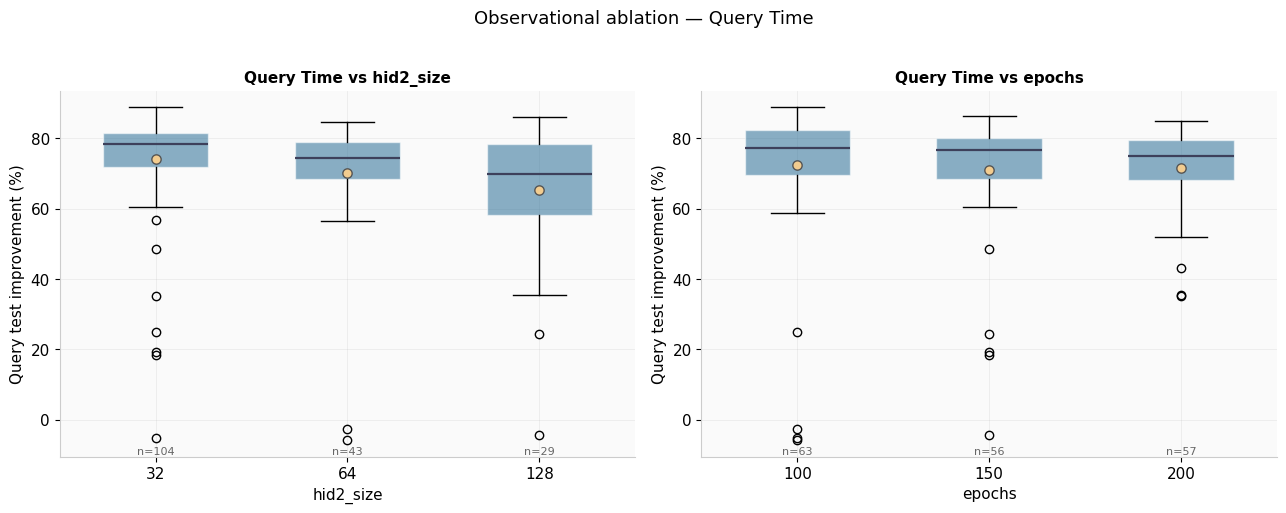

hid2_size: 32: 74.1% | 64: 70.0% | 128: 65.3%
epochs: 100: 72.4% | 150: 70.9% | 200: 71.5%


In [27]:
# J1 — Observational ablation (Query Time, test): effect of model size. No causal claim.
CONFIG_COLS = ['embed_dim','hid1_size','hid2_size','pred_hid','lr','epochs']
frames=[]
for prefix in ['hp','smac','random']:
    for objective in ['total','query']:
        for tag in ['seed42_10','seed42_25','seed123_25']:
            fn=os.path.join(DRIVE_PATH, f'{prefix}_{objective}_{tag}.csv')
            if os.path.exists(fn): frames.append(pd.read_csv(fn))
pool=pd.concat(frames, ignore_index=True); pool=pool[pool['obj_val']<9999].drop_duplicates(subset=CONFIG_COLS, keep='first')
print('Distinct configs pooled:', len(pool))
factors=[('hid2_size',[32,64,128]), ('epochs',[100,150,200])]
fig, axes=plt.subplots(1,2, figsize=(13,5))
for j,(fac,order) in enumerate(factors):
    ax=axes[j]
    data=[pool[pool[fac]==v]['query_impr_test'].values for v in order]
    bp=ax.boxplot(data, patch_artist=True, widths=0.55, medianprops={'color':'#3D405B','linewidth':1.6})
    ax.set_xticks(range(1,len(order)+1)); ax.set_xticklabels([str(v) for v in order])
    for patch in bp['boxes']: patch.set_facecolor(PALETTE['tpe']); patch.set_alpha(0.55); patch.set_edgecolor('white')
    for k,v in enumerate(order,1):
        vals=pool[pool[fac]==v]['query_impr_test'].values
        if len(vals):
            ax.scatter([k],[vals.mean()], color=PALETTE['accent'], edgecolor='#555', zorder=5, s=45)
            ax.text(k, ax.get_ylim()[0], f'n={len(vals)}', ha='center', va='bottom', fontsize=8, color='#666')
    ax.set_xlabel(fac); ax.set_ylabel('Query test improvement (%)')
    ax.set_title(f'Query Time vs {fac}', fontsize=11, fontweight='bold')
fig.suptitle('Observational ablation — Query Time', fontsize=13, y=1.02)
plt.tight_layout()
out=os.path.join(DRIVE_PATH,'ablation_query.png'); plt.savefig(out,dpi=150,bbox_inches='tight',facecolor='white'); plt.show()
for fac,order in factors:
    print(f'{fac}: ' + ' | '.join(f'{v}: {pool[pool[fac]==v].query_impr_test.mean():.1f}%' for v in order))

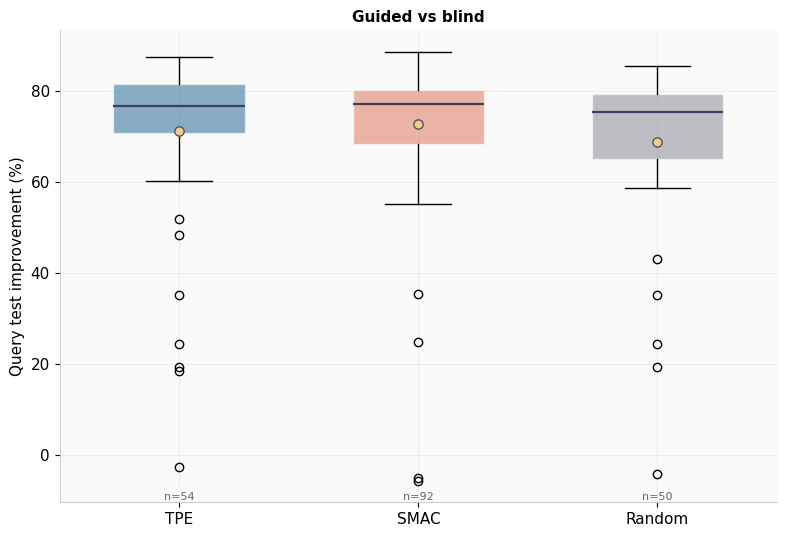

In [25]:
# K1 — Distribution of explored configs per algorithm (Query Time, test): guided vs blind.
CONFIG_COLS=['embed_dim','hid1_size','hid2_size','pred_hid','lr','epochs']
ALGOS=[('hp','TPE'),('smac','SMAC'),('random','Random')]
def _algo_pool(prefix):
    frames=[]
    for objective in ['total','query']:
        for tag in ['seed42_10','seed42_25','seed123_25']:
            fn=os.path.join(DRIVE_PATH, f'{prefix}_{objective}_{tag}.csv')
            if os.path.exists(fn): frames.append(pd.read_csv(fn))
    if not frames: return None
    d=pd.concat(frames, ignore_index=True); d=d[d['obj_val']<9999]
    return d.drop_duplicates(subset=CONFIG_COLS, keep='first')
data,labels,cols=[],[],[]
for prefix,algo in ALGOS:
    d=_algo_pool(prefix)
    if d is None or d.empty: continue
    data.append(d['query_impr_test'].values); labels.append(algo); cols.append(PALETTE[algo.lower()])
fig,ax=plt.subplots(figsize=(8,5.5))
bp=ax.boxplot(data, patch_artist=True, widths=0.55, medianprops={'color':'#3D405B','linewidth':1.6})
ax.set_xticks(range(1,len(labels)+1)); ax.set_xticklabels(labels)
for patch,c in zip(bp['boxes'],cols): patch.set_facecolor(c); patch.set_alpha(0.55); patch.set_edgecolor('white')
for k,dd in enumerate(data,1):
    ax.scatter([k],[np.mean(dd)], color=PALETTE['accent'], edgecolor='#555', zorder=5, s=45)
    ax.text(k, ax.get_ylim()[0], f'n={len(dd)}', ha='center', va='bottom', fontsize=8, color='#666')
ax.set_ylabel('Query test improvement (%)')
ax.set_title('Guided vs blind', fontsize=11, fontweight='bold')
plt.tight_layout()
out=os.path.join(DRIVE_PATH,'distribution_query.png'); plt.savefig(out,dpi=150,bbox_inches='tight',facecolor='white'); plt.show()

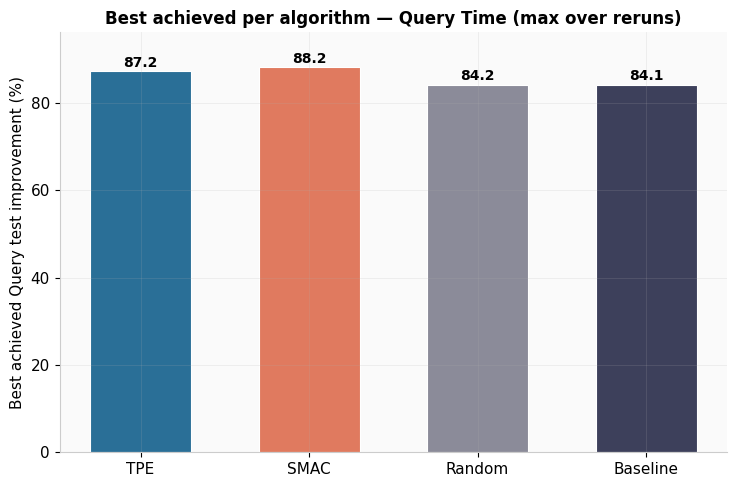

In [28]:
# K2 — Best achieved per algorithm (Query Time, max over reruns). Complementary to mean±std.
df=_load_rerun_csv()
if df.empty: print('Need reruns.')
else:
    order=[a for a in ['TPE','SMAC','Random','Baseline'] if (df['algo']==a).any()]
    cols=[PALETTE[a.lower()] for a in order]
    vals=[df[df['algo']==a]['query_impr_test'].max() for a in order]
    x=np.arange(len(order))
    fig,ax=plt.subplots(figsize=(7.5,5))
    ax.bar(x, vals, color=cols, edgecolor='white', linewidth=0.8, width=0.6)
    for xi,v in zip(x,vals): ax.text(xi, v+0.4, f'{v:.1f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_xticks(x); ax.set_xticklabels(order); ax.set_ylabel('Best achieved Query test improvement (%)'); ax.set_ylim(0, max(vals)+8)
    ax.set_title('Best achieved per algorithm — Query Time (max over reruns)', fontsize=12, fontweight='bold')
    plt.tight_layout()
    out=os.path.join(DRIVE_PATH,'best_achieved_query.png'); plt.savefig(out,dpi=150,bbox_inches='tight',facecolor='white'); plt.show()


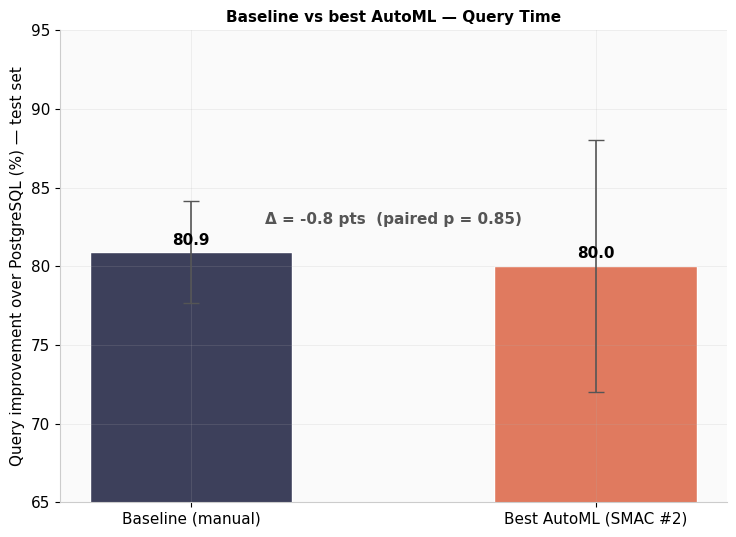

Baseline 80.9±3.2 | Best AutoML (SMAC #2) 80.0±8.0 | Δ=-0.8, p=0.851


In [29]:
# K4 — Baseline vs best AutoML (validation-selected) — Query Time, test set. Signed Δ + paired p.
from scipy import stats
df=_load_rerun_csv()
if df.empty or (df['algo']=='Baseline').sum()==0: print('Need reruns incl. Baseline.')
else:
    df['sig']=df.apply(lambda r:(int(r.embed_dim),int(r.hid1_size),int(r.hid2_size),int(r.pred_hid),round(float(r.lr),8),int(r.epochs)),axis=1)
    b=df[df.algo=='Baseline']; base_m,base_s=b['query_impr_test'].mean(), b['query_impr_test'].std()
    nb=df[df.algo!='Baseline'].copy()
    agg=nb.groupby('sig').agg(qv=('query_impr_val','mean'), q=('query_impr_test','mean'),
                              qs=('query_impr_test','std'), algo=('algo','first'), rank=('rank','first')).reset_index()
    win=agg.sort_values('qv', ascending=False).iloc[0]
    wl=f"Best AutoML ({win['algo']} #{int(win['rank'])})"
    ws=df[df.sig==win['sig']].sort_values('train_seed')['query_impr_test'].values
    bs=b.sort_values('train_seed')['query_impr_test'].values
    t,p=stats.ttest_rel(ws,bs); d=win['q']-base_m
    m=[base_m, win['q']]; s=[base_s, win['qs']]; labels=['Baseline (manual)', wl]
    lo=max(int((min(m)-max(s)-3)//5*5),0); hi=int((max(m)+max(s)+3)//5*5+5)
    x=np.arange(2)
    fig,ax=plt.subplots(figsize=(7.5,5.5))
    ax.bar(x,m,0.5,yerr=s,capsize=6,color=[PALETTE['baseline'],PALETTE['smac']],edgecolor='white',error_kw={'elinewidth':1.2,'ecolor':'#555'})
    for xi,v in zip(x,m): ax.text(xi, v+0.3, f'{v:.1f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax.annotate(f'Δ = {d:+.1f} pts  (paired p = {p:.2f})', xy=(0.5, max(m)+(hi-lo)*0.06), ha='center', fontsize=11, fontweight='bold', color='#555')
    ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(lo,hi)
    ax.set_ylabel('Query improvement over PostgreSQL (%) — test set')
    ax.set_title('Baseline vs best AutoML — Query Time', fontsize=11, fontweight='bold')
    plt.tight_layout()
    out=os.path.join(DRIVE_PATH,'baseline_vs_best_query.png'); plt.savefig(out,dpi=150,bbox_inches='tight',facecolor='white'); plt.show()
    print(f"Baseline {base_m:.1f}±{base_s:.1f} | {wl} {win['q']:.1f}±{win['qs']:.1f} | Δ={d:+.1f}, p={p:.3f}")

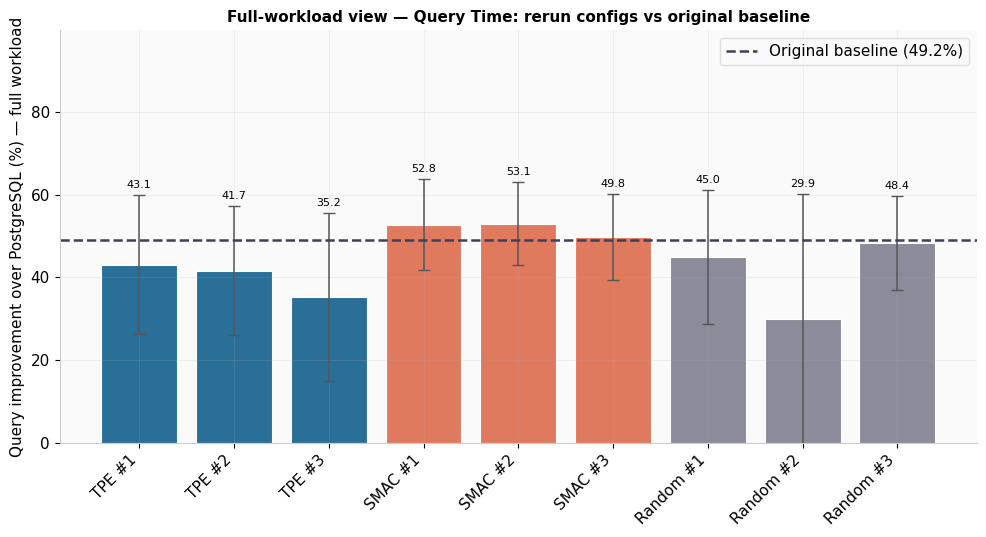

In [30]:
# K5 — Full-workload view (Query Time): rerun configs vs ORIGINAL baseline (dashed). Comparable to the paper.
BASELINE_FULL_Q = 49.2   # original B2 run, full workload, Query
df=_load_rerun_csv()
if df.empty: print('Need reruns.')
else:
    df['sig']=df.apply(lambda r:(int(r.embed_dim),int(r.hid1_size),int(r.hid2_size),int(r.pred_hid),round(float(r.lr),8),int(r.epochs)),axis=1)
    g=df.groupby('sig').agg(q_mean=('query_impr_full','mean'), q_std=('query_impr_full','std')).to_dict('index')
    labels,qm,qs,colors=[],[],[],[]; seen=set()
    for cfg in RERUN_CONFIGS:
        if cfg['algo']=='Baseline': continue
        sig=_cfg_sig(cfg)
        if sig not in g or sig in seen: continue
        seen.add(sig); a=g[sig]
        labels.append(f"{cfg['algo']} #{cfg['rank']}")
        qm.append(a['q_mean']); qs.append(0 if np.isnan(a['q_std']) else a['q_std']); colors.append(PALETTE.get(cfg['algo'].lower(),'#888'))
    x=np.arange(len(labels))
    fig,ax=plt.subplots(figsize=(10,5.5))
    ax.bar(x,qm,yerr=qs,color=colors,capsize=4,edgecolor='white',linewidth=0.8,error_kw={'elinewidth':1.1,'ecolor':'#555'})
    ax.axhline(BASELINE_FULL_Q, color=PALETTE['baseline'], ls='--', lw=1.8, label=f'Original baseline ({BASELINE_FULL_Q:.1f}%)')
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_ylabel('Query improvement over PostgreSQL (%) — full workload')
    top=max(qm+[BASELINE_FULL_Q])+max(qs+[1]); ax.set_ylim(0, top*1.2)
    for xi,v,e in zip(x,qm,qs): ax.text(xi, v+e+top*0.015, f'{v:.1f}', ha='center', va='bottom', fontsize=8)
    ax.legend(loc='upper right')
    ax.set_title('Full-workload view — Query Time: rerun configs vs original baseline', fontsize=11, fontweight='bold')
    plt.tight_layout()
    out=os.path.join(DRIVE_PATH,'fullworkload_query.png'); plt.savefig(out,dpi=150,bbox_inches='tight',facecolor='white'); plt.show()